# S08 · Laboratory — Localization: EKF and particles

**Robotic Systems (295II235) · EEBE–UPC · Probabilistic Robotics, Session 02 (course session S08)**

Today a robot drives a figure of eight in a 20 m × 20 m arena with eight landmarks, and you localize it twice:
with an **extended Kalman filter** and with a **particle filter** (Monte Carlo localization). Then you break both
and compare them.

| Part | Content |
|---|---|
| 1 | **EKF localization.** Two Jacobians and the correction step (**TODO**); a run from a known start, animated; experiments with what the filter believes about the noise (**your settings**); then a kidnapping. |
| 2 | **Monte Carlo localization.** The measurement likelihood of a particle (**TODO**); global localization from nothing; then too few particles and the kidnapping again. |
| 3 | **The comparison.** The same runs measured side by side; your table and two sentences. |

**How to work**

- Run the cells in order. Cells marked **Provided** simulate the robot, run the filters and draw the plots: read
  them if you are curious, but do not edit them.
- Cells marked **TODO** are yours. Each is followed by a **self-check** cell that tells you whether your result is
  right. Cells marked **Answer** are short written answers (two or three sentences).
- Only `numpy` and `matplotlib` are needed; the notebook runs as is in Google Colab or any Jupyter environment.
- Your data depend on your `STUDENT_ID`: every student gets a slightly different robot and sensor.

**Hand in** this notebook, executed, with the answer cells and the Part 3 table filled in, before the start of
session S09 (Wednesday 11 November 2026, 14:59), as the `.ipynb` and a PDF printout.

Related slides: *Taylor: the tangent at the mean*, *The Jacobians of localization*, *The EKF localization
algorithm*, *Data association*, *The particle filter*, *Monte Carlo localization*, *Resampling*, *Particle
deprivation*, *Augmented MCL*, *EKF or particles?*.

## 0 · Setup

Write your UPC username (for example `nom.cognom`) in `STUDENT_ID` and run the cell. It seeds the random
generator that builds your data, so keep it the same every time you run the notebook.

In [1]:
STUDENT_ID = 'L73MC6F1W'          # <-- your UPC username, e.g. 'nom.cognom'

import zlib
import numpy as np
import matplotlib.pyplot as plt

if not STUDENT_ID.strip():
    raise ValueError('Write your UPC username in STUDENT_ID and run this cell again.')
SEED = zlib.crc32(STUDENT_ID.strip().lower().encode())
print(f'Seed for {STUDENT_ID!r}: {SEED}')

# --- plotting style (course palette) --------------------------------------------------------------------
BLUE, ORANGE, GOLD, LIGHT = '#017BC1', '#C8551E', '#D9A21B', '#6CB4E4'
NAVY, GREY, INK, TINT = '#0A3F66', '#7F7F7F', '#262626', '#D5E6F2'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.edgecolor': GREY, 'axes.labelcolor': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': NAVY, 'axes.grid': True,
    'grid.color': '#DDDDDD', 'grid.linewidth': 0.6, 'xtick.color': GREY, 'ytick.color': GREY,
    'lines.linewidth': 1.8, 'legend.fontsize': 9, 'legend.framealpha': 0.9, 'legend.edgecolor': 'none',
    'axes.spines.top': False, 'axes.spines.right': False})

Seed for 'L73MC6F1W': 2969788782


In [2]:
#@title Provided: the world, the simulator, the filters' machinery and the plots (run it, do not edit)
from matplotlib import animation
from IPython.display import HTML, display
import time

# ---- S08 lab core: world, simulator, models (embedded in the provided cell) ----
ARENA = 20.0                                   # square arena [m]
LANDMARKS = np.array([[3.0, 4.0], [10.0, 4.5], [17.0, 5.0], [19.0, 12.0],
                      [14.0, 17.0], [6.0, 16.5], [1.0, 11.0], [10.0, 15.0]])
COLOURS = np.array([0, 1, 2, 3, 0, 1, 2, 3])     # each landmark has one of four colours: two of each, far apart
COLOUR_NAMES = ['red', 'green', 'blue', 'yellow']
DT = 0.1                                       # time step [s]
T_END = 90.0                                   # length of the run [s]
MAX_RANGE, FOV = 6.0, np.pi / 2                # sensor: range [m] and half field of view [rad]
X0 = np.array([10.0, 10.0, np.pi / 2])          # start pose (x, y, theta)
KIDNAP_T = 40.0                                # kidnapping: the robot is carried to the mirror pose through the centre

_g = np.random.default_rng(SEED + 21)
A_NOISE = np.round(_g.uniform([0.02, 0.005, 0.01, 0.02], [0.04, 0.010, 0.02, 0.04]), 4)   # a1 ... a4
SIGMA_R = round(float(_g.uniform(0.10, 0.20)), 3)                                       # range noise [m]
SIGMA_PHI = round(float(np.radians(_g.uniform(2.0, 4.0))), 4)                            # bearing noise [rad]
Q = np.diag([SIGMA_R ** 2, SIGMA_PHI ** 2])


def wrap_angle(a):
    return (np.asarray(a) + np.pi) % (2 * np.pi) - np.pi


def controls():
    """Commanded (v, omega) for every step: a figure of eight, two circles of radius 4 m."""
    n = int(round(T_END / DT))
    t = np.arange(n) * DT
    v = np.full(n, 1.0)
    period = 2 * np.pi / 0.25
    w = np.where((t // period) % 2 == 0, 0.25, -0.25)
    return np.column_stack([v, w])


def g(u, x, dt=DT):
    """Velocity motion model, noise-free part (works on one pose (3,) or many (M, 3))."""
    x = np.asarray(x, float)
    v, w = u
    th = x[..., 2]
    if abs(w) < 1e-6:
        d = np.stack([v * dt * np.cos(th), v * dt * np.sin(th), np.zeros_like(th)], -1)
    else:
        r = v / w
        d = np.stack([-r * np.sin(th) + r * np.sin(th + w * dt), r * np.cos(th) - r * np.cos(th + w * dt),
                      np.full_like(th, w * dt)], -1)
    out = x + d
    out[..., 2] = wrap_angle(out[..., 2])
    return out


def h(x, landmark):
    """Range and bearing of one landmark (2,) seen from pose x (3,) or poses (M, 3)."""
    x = np.asarray(x, float)
    dx, dy = landmark[0] - x[..., 0], landmark[1] - x[..., 1]
    return np.stack([np.hypot(dx, dy), wrap_angle(np.arctan2(dy, dx) - x[..., 2])], -1)


def M_noise(u):
    v, w = u
    a1, a2, a3, a4 = A_NOISE
    return np.diag([a1 * v ** 2 + a2 * w ** 2, a3 * v ** 2 + a4 * w ** 2])


def V_jacobian(u, mu, dt=DT):
    """Jacobian of g with respect to the control (v, omega), Thrun et al. eq. 7.11."""
    v, w = u
    th = mu[2]
    s, c, s2, c2 = np.sin(th), np.cos(th), np.sin(th + w * dt), np.cos(th + w * dt)
    return np.array([[(-s + s2) / w, v * (s - s2) / w ** 2 + v * c2 * dt / w],
                     [(c - c2) / w, -v * (c - c2) / w ** 2 + v * s2 * dt / w],
                     [0.0, dt]])


def simulate(seed, kidnap=False, sensor_scale=1.0, max_range=None):
    """Ground truth, commands and readings. z[k]: array of rows (range, bearing, colour), one per landmark seen at
    step k, in no particular order: two landmarks share each colour, so a reading does not say which one it was. true_id[k]: which landmark it was (for
    checking only; the filters do not use it)."""
    g_ = np.random.default_rng(seed)
    max_range = MAX_RANGE if max_range is None else max_range
    U = controls()
    n = len(U)
    x = np.zeros((n + 1, 3)); x[0] = X0
    z, ids = [np.zeros((0, 3))], [np.zeros(0, int)]
    for k in range(n):
        v, w = U[k]
        sd = np.sqrt(np.diag(M_noise(U[k])))
        u_exec = (v + g_.normal(0, sd[0]), w + g_.normal(0, sd[1]))
        x[k + 1] = g(u_exec, x[k])
        if kidnap and abs((k + 1) * DT - KIDNAP_T) < DT / 2:
            x[k + 1] = [ARENA - x[k + 1, 0], ARENA - x[k + 1, 1], wrap_angle(x[k + 1, 2] + np.pi)]
        rows = []
        for j, m in enumerate(LANDMARKS):
            r, phi = h(x[k + 1], m)
            if r < max_range and abs(phi) < FOV:
                rows.append([r + g_.normal(0, sensor_scale * SIGMA_R), wrap_angle(phi + g_.normal(0, sensor_scale * SIGMA_PHI)),
                             COLOURS[j], j])
        rows = np.array(rows).reshape(-1, 4)
        rows = rows[g_.permutation(len(rows))]          # readings come in no particular order
        z.append(rows[:, :3]); ids.append(rows[:, 3].astype(int))
    return {'t': np.arange(n + 1) * DT, 'x': x, 'u': U, 'z': z, 'true_id': ids}


def ekf_predict(mu, Sigma, u, m_scale=1.0):
    G = G_jacobian(u, mu)
    V = V_jacobian(u, mu)
    return g(u, mu), G @ Sigma @ G.T + V @ (m_scale * M_noise(u)) @ V.T


GATE = 9.21                                    # chi-square, 2 degrees of freedom, 99 %


def associate(mu_bar, Sigma_bar, z):
    """Maximum-likelihood data association (slide 26): the landmark with the smallest Mahalanobis distance,
    or None if even the best one is outside the gate. Uses your h-Jacobian."""
    best, best_d2 = None, GATE
    for j in np.flatnonzero(COLOURS == int(z[2])):
        m = LANDMARKS[j]
        H = H_jacobian(mu_bar, m)
        S = H @ Sigma_bar @ H.T + Q
        nu = z[:2] - h(mu_bar, m); nu[1] = wrap_angle(nu[1])
        d2 = float(nu @ np.linalg.solve(S, nu))
        if d2 < best_d2:
            best, best_d2 = j, d2
    return best


EKF_STATS = {}


def run_ekf(data, mu0, Sigma0, q_scale=1.0, m_scale=1.0):
    """EKF localization with your G_jacobian, H_jacobian and ekf_correct; landmarks associated by maximum likelihood.
    q_scale, m_scale: multiply the sensor and motion covariances the filter BELIEVES (1 = the true ones).
    Counts of readings used, rejected by the gate, and associated with the wrong landmark go to EKF_STATS."""
    global Q
    Q_true = Q
    Q = q_scale * Q_true                       # the filter's belief about the sensor (used by associate and ekf_correct)
    try:
        mu, Sigma = np.array(mu0, float), np.array(Sigma0, float)
        mus, Sigmas = [mu.copy()], [Sigma.copy()]
        used = rejected = wrong = 0
        for k in range(len(data['u'])):
            mu, Sigma = ekf_predict(mu, Sigma, data['u'][k], m_scale)
            for zi, tid in zip(data['z'][k + 1], data['true_id'][k + 1]):
                j = associate(mu, Sigma, zi)
                if j is None:
                    rejected += 1
                    continue
                used += 1; wrong += int(j != tid)
                mu, Sigma = ekf_correct(mu, Sigma, zi[:2], LANDMARKS[j])
            mus.append(mu.copy()); Sigmas.append(Sigma.copy())
    finally:
        Q = Q_true
    EKF_STATS.update(used=used, rejected=rejected, wrong=wrong)
    return np.array(mus), np.array(Sigmas)


def sample_motion(u, particles, g_):
    """Velocity motion model, sampled: every particle gets its own noisy (v, omega)."""
    M = len(particles)
    sd = np.sqrt(np.diag(M_noise(u)))
    v = u[0] + g_.normal(0, sd[0], M)
    w = u[1] + g_.normal(0, sd[1], M)
    th = particles[:, 2]
    r = v / w
    out = particles.copy()
    out[:, 0] += -r * np.sin(th) + r * np.sin(th + w * DT)
    out[:, 1] += r * np.cos(th) - r * np.cos(th + w * DT)
    out[:, 2] = wrap_angle(th + w * DT)
    return out


def low_variance_resample(particles, w, g_):
    """Thrun et al. Table 4.4: one random number, M equally spaced pointers on the cumulative weights."""
    M = len(particles)
    pointers = g_.uniform(0, 1 / M) + np.arange(M) / M
    idx = np.searchsorted(np.cumsum(w), pointers)
    return particles[np.minimum(idx, M - 1)]


def uniform_particles(M, g_):
    return np.column_stack([g_.uniform(0, ARENA, M), g_.uniform(0, ARENA, M), g_.uniform(-np.pi, np.pi, M)])


def run_mcl(data, M, seed, augmented=False, inflate=1.0, a_slow=0.005, a_fast=0.3, keep_every=10, x0=None, c_inj=0.3):
    """Monte Carlo localization with your log_likelihood. x0=None: particles uniform over the arena (global
    localization); x0 = a pose: particles around it (tracking from a known start)."""
    g_ = np.random.default_rng(seed)
    if x0 is None:
        P = uniform_particles(M, g_)
    else:
        P = np.asarray(x0, float) + g_.normal(0, 1, (M, 3)) * [0.1, 0.1, np.radians(5)]
    w_slow = w_fast = None
    est, spread, kept, wbar_hist = [], [], [P.copy()], []
    for k in range(len(data['u'])):
        P = sample_motion(data['u'][k], P, g_)
        z = data['z'][k + 1]
        if len(z):
            logw = np.asarray(log_likelihood(P, z, inflate * SIGMA_R, inflate * SIGMA_PHI), float)
            wbar = float(np.mean(np.exp(logw / len(z))))     # per reading, so that it does not depend on how many are seen
            w = np.exp(logw - logw.max()); w /= w.sum()
            if augmented:
                w_slow = wbar if w_slow is None else w_slow + a_slow * (wbar - w_slow)
                w_fast = wbar if w_fast is None else w_fast + a_fast * (wbar - w_fast)
            P = low_variance_resample(P, w, g_)
            if augmented and w_slow > 0:
                p_rand = max(0.0, 1.0 - w_fast / (c_inj * w_slow))
                n_rand = g_.binomial(M, p_rand)
                if n_rand:
                    P[g_.choice(M, n_rand, replace=False)] = uniform_particles(n_rand, g_)
            wbar_hist.append(wbar)
        else:
            wbar_hist.append(np.nan)
        c, s = np.cos(P[:, 2]).mean(), np.sin(P[:, 2]).mean()
        est.append([P[:, 0].mean(), P[:, 1].mean(), np.arctan2(s, c)])
        spread.append(np.sqrt(P[:, 0].var() + P[:, 1].var()))
        if (k + 1) % keep_every == 0:
            kept.append(P.copy())
    est = np.vstack([[np.nan, np.nan, np.nan], est])
    return {'est': est, 'spread': np.r_[np.nan, spread], 'particles': kept, 'wbar': np.r_[np.nan, wbar_hist]}




# ---- plotting helpers ----
LM_COLOURS = ['#C0392B', '#2E8B57', '#017BC1', '#D9A21B']     # red, green, blue, yellow landmarks

def _arena(ax, title=None):
    ax.set_xlim(-0.5, ARENA + 0.5); ax.set_ylim(-0.5, ARENA + 0.5); ax.set_aspect('equal')
    for j, (lx, ly) in enumerate(LANDMARKS):
        ax.plot(lx, ly, '*', color=LM_COLOURS[COLOURS[j]], ms=14, mec=INK, mew=0.6, zorder=5)
        ax.annotate(str(j), (lx, ly), xytext=(5, 5), textcoords='offset points', fontsize=8, color=NAVY)
    ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
    if title: ax.set_title(title, loc='left')


def _robot(ax, pose, color=ORANGE, size=0.6, **kw):
    x, y, th = pose
    tri = np.array([[size, 0], [-0.6 * size, 0.45 * size], [-0.6 * size, -0.45 * size]])
    R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    p = tri @ R.T + [x, y]
    ax.fill(p[:, 0], p[:, 1], facecolor='none', edgecolor=color, lw=1.6, zorder=6, **kw)    # outline: particles stay visible


def _ellipse(ax, mu, S2, k=3.0, **kw):
    vals, vecs = np.linalg.eigh(S2)
    t = np.linspace(0, 2 * np.pi, 60)
    c = np.stack([np.cos(t), np.sin(t)])
    pts = (vecs @ (np.sqrt(np.maximum(vals, 0))[:, None] * c)) * k + np.asarray(mu)[:, None]
    ax.plot(pts[0], pts[1], **kw)


def plot_world(data):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={'width_ratios': [1, 1.1]})
    _arena(a1, f'The world: landmarks, true path, readings at t = {data["t"][int(len(data["t"]) * 0.3)]:.0f} s')
    a1.plot(data['x'][:, 0], data['x'][:, 1], '--', color=INK, lw=1.2, label='true path')
    k = int(len(data['t']) * 0.3)
    x, y, th = data['x'][k]
    for r, phi, c in data['z'][k]:
        a1.plot([x, x + r * np.cos(th + phi)], [y, y + r * np.sin(th + phi)], color=LM_COLOURS[int(c)], lw=1.2)
    _robot(a1, data['x'][k]); a1.legend(loc='lower right', fontsize=8)
    n = np.array([len(z) for z in data['z']])
    a2.step(data['t'], n, where='post', color=BLUE)
    a2.set_xlabel('time [s]'); a2.set_ylabel('landmarks seen'); a2.set_title('Readings per step', loc='left')
    plt.tight_layout(); plt.show()


def plot_ekf(data, mus, Sigmas, title='EKF localization', every=20):
    T = data['t']
    e = data['x'][:, :2] - mus[:, :2]
    fig = plt.figure(figsize=(13, 5.2))
    a1 = fig.add_axes([0.04, 0.1, 0.42, 0.82]); a2 = fig.add_axes([0.55, 0.56, 0.43, 0.36]); a3 = fig.add_axes([0.55, 0.1, 0.43, 0.36])
    _arena(a1, title)
    a1.plot(data['x'][:, 0], data['x'][:, 1], '--', color=INK, lw=1.1, label='truth')
    a1.plot(mus[:, 0], mus[:, 1], color=BLUE, lw=1.4, label='EKF')
    for k in range(0, len(T), every):
        _ellipse(a1, mus[k, :2], Sigmas[k][:2, :2], color=LIGHT, lw=0.9)
    a1.plot([], [], color=LIGHT, label='3σ ellipses'); a1.legend(loc='lower right', fontsize=8)
    sig = np.sqrt(Sigmas[:, 0, 0] + Sigmas[:, 1, 1])
    a2.plot(T, np.hypot(*e.T), color=BLUE, label='position error')
    a2.plot(T, 3 * sig, ':', color=GREY, label='3σ (x and y combined)')
    a2.set_ylabel('m'); a2.legend(fontsize=8); a2.set_title('Error and its 3σ bound', loc='left')
    eth = np.degrees(wrap_angle(data['x'][:, 2] - mus[:, 2]))
    a3.plot(T, eth, color=ORANGE, label='heading error'); a3.plot(T, 3 * np.degrees(np.sqrt(Sigmas[:, 2, 2])), ':', color=GREY)
    a3.plot(T, -3 * np.degrees(np.sqrt(Sigmas[:, 2, 2])), ':', color=GREY, label='±3σ')
    a3.set_xlabel('time [s]'); a3.set_ylabel('deg'); a3.legend(fontsize=8)
    plt.show()


def plot_mcl_snapshots(data, res, times=(0, 1, 3, 6, 10, 20), keep_every=10):
    fig, axes = plt.subplots(1, len(times), figsize=(2.6 * len(times), 3))
    for ax, t in zip(axes, times):
        i = int(round(t / (DT * keep_every)))
        P = res['particles'][i]
        _arena(ax); ax.set_xlabel(''); ax.set_ylabel('')
        ax.plot(P[:, 0], P[:, 1], '.', color=BLUE, ms=1.5, alpha=0.6, zorder=7)
        _robot(ax, data['x'][int(round(t / DT))], size=1.0)
        ax.set_title(f't = {t} s', loc='left', fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()


def animate_mcl(data, res, keep_every=10, step=2):
    fig, ax = plt.subplots(figsize=(5.2, 5.2))
    n = len(res['particles'])
    frames = list(range(0, min(10, n))) + list(range(10, n, step))     # every frame at first, then every step-th
    def draw(f):
        ax.clear(); _arena(ax)
        P = res['particles'][f]
        ax.plot(P[:, 0], P[:, 1], '.', color=BLUE, ms=1.5, alpha=0.6, zorder=7)
        _robot(ax, data['x'][min(f * keep_every, len(data['x']) - 1)], size=0.9)
        ax.set_title(f'particles at t = {f * keep_every * DT:.1f} s', loc='left')
    anim = animation.FuncAnimation(fig, draw, frames=frames, interval=300)
    plt.close(fig)
    return HTML(anim.to_jshtml())


def plot_errors(data, curves, title, ylim=None):
    fig, ax = plt.subplots(figsize=(11, 3.4))
    for est, lab, c in curves:
        ax.plot(data['t'], np.hypot(*(data['x'][:, :2] - est[:, :2]).T), color=c, label=lab, lw=1.4)
    if 'kidnap' in title.lower():
        ax.axvline(KIDNAP_T, color=GREY, ls=':', lw=1); ax.text(KIDNAP_T + 0.5, ax.get_ylim()[1] * 0.9, 'kidnapping', color=GREY, fontsize=9)
    ax.set_xlabel('time [s]'); ax.set_ylabel('position error [m]'); ax.set_yscale('log')
    if ylim: ax.set_ylim(*ylim)
    ax.legend(fontsize=8); ax.set_title(title, loc='left')
    plt.tight_layout(); plt.show()


def animate_ekf(data, mus, Sigmas, every=20, title='EKF'):
    """The run as an animation: truth (outline) and estimate (filled), 3σ ellipse, readings of the moment."""
    fig, ax = plt.subplots(figsize=(5.2, 5.2), dpi=72)
    frames = list(range(0, len(data['t']), every))
    def draw(k):
        ax.clear(); _arena(ax)
        ax.plot(data['x'][:k + 1, 0], data['x'][:k + 1, 1], '--', color=INK, lw=0.9)
        ax.plot(mus[:k + 1, 0], mus[:k + 1, 1], color=BLUE, lw=1.2)
        x, y, th = data['x'][k]
        for r, phi, c in data['z'][k]:
            ax.plot([x, x + r * np.cos(th + phi)], [y, y + r * np.sin(th + phi)], color=LM_COLOURS[int(c)], lw=1)
        _ellipse(ax, mus[k, :2], Sigmas[k][:2, :2], color=BLUE, lw=1.3)
        _robot(ax, data['x'][k], size=0.8)
        mx, my, mth = mus[k]
        tri = np.array([[0.8, 0], [-0.48, 0.36], [-0.48, -0.36]]) @ np.array([[np.cos(mth), np.sin(mth)], [-np.sin(mth), np.cos(mth)]]) + [mx, my]
        ax.fill(tri[:, 0], tri[:, 1], color=BLUE, alpha=0.8, zorder=7)
        e = np.hypot(x - mx, y - my)
        ax.set_title(f'{title} · t = {data["t"][k]:.0f} s · error {e:.2f} m', loc='left', fontsize=10)
    anim = animation.FuncAnimation(fig, draw, frames=frames, interval=250)
    plt.close(fig)
    return HTML(anim.to_jshtml())


DATA = simulate(SEED + 22)                      # the run used in parts 1, 2 and 3
DATA_K = simulate(SEED + 25, kidnap=True)       # the same kind of run, with a kidnapping at t = 40 s
print(f'Your robot: motion noise a1..a4 = {A_NOISE.tolist()}')
print(f'Your sensor: sigma_r = {SIGMA_R} m, sigma_phi = {np.degrees(SIGMA_PHI):.2f} deg, range {MAX_RANGE} m, '
      f'field of view ±{np.degrees(FOV):.0f} deg')

Your robot: motion noise a1..a4 = [0.0237, 0.005, 0.0149, 0.0332]
Your sensor: sigma_r = 0.191 m, sigma_phi = 3.16 deg, range 6.0 m, field of view ±90 deg


## 0.1 · The world and the data

The state is the pose $x = (x, y, \theta)$: position in metres and heading $\theta$ in radians, measured from the
$x$ axis, counter-clockwise. The robot is commanded $u = (v, \omega)$ = (1 m/s, ±0.25 rad/s) every
$\Delta t = 0.1$ s: two circles of radius 4 m, a figure of eight. What it executes is the command plus noise
(the **velocity motion model** with parameters $a_1 \dots a_4$, slide *The velocity motion model*, S07).

The sensor sees landmarks closer than 6 m and within ±90° of the heading. Each reading is a row
`(range, bearing, colour)`. The eight landmarks come in **four colours, two of each**, placed far apart: a
reading tells you the colour, not which of the two landmarks it was. The rows of one step come in no particular
order.

`DATA` is a dictionary:

| key | shape | content |
|---|---|---|
| `'t'` | (901,) | time [s] |
| `'x'` | (901, 3) | true pose at every step (for plotting and scoring only: the filters never see it) |
| `'u'` | (900, 2) | command $(v, \omega)$ applied between step $k$ and $k+1$ |
| `'z'` | list of 901 arrays | `z[k]` has one row `(range, bearing, colour)` per landmark seen at step $k$ (possibly none) |
| `'true_id'` | list of 901 arrays | which landmark each row really was (for checking only) |

The provided cell also defines the models you need: `g(u, x)` (noise-free motion), `h(x, landmark)` (expected
range and bearing of one landmark), `M_noise(u)` (covariance of the control noise), `V_jacobian(u, mu)`,
`Q` (covariance of one reading), `LANDMARKS` (8 × 2), `COLOURS` (8,) and `wrap_angle(a)`.

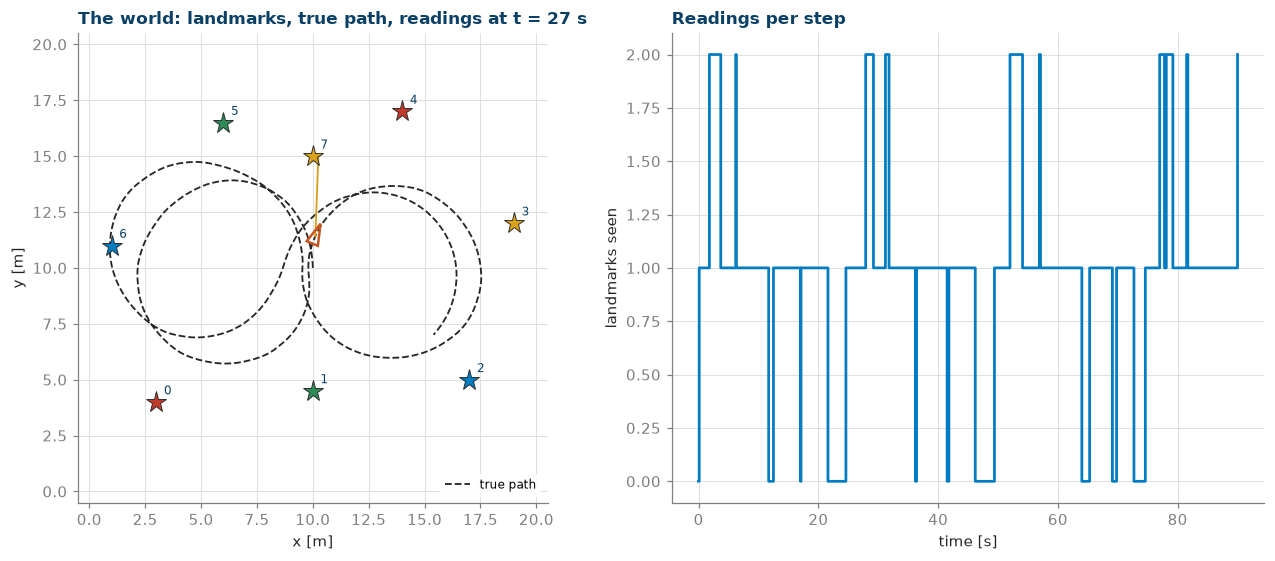

first readings: [[5.058, -0.034, 3.0]]


In [3]:
plot_world(DATA)
print('first readings:', DATA['z'][1].round(3).tolist())

---
# Part 1 · EKF localization

The EKF keeps one Gaussian, mean $\mu$ and covariance $\Sigma$, and linearizes $g$ and $h$ at the current mean
(slides *Taylor: the tangent at the mean* and *The EKF*). The provided cell has the prediction already:
$$\bar\mu = g(u, \mu), \qquad \bar\Sigma = G\,\Sigma\,G^\top + V\,M\,V^\top,$$
which needs your **G**. For every reading, the provided `associate` picks the landmark of that colour with the
smallest Mahalanobis distance (slide *Data association*), which needs your **H**, and then calls your
`ekf_correct`.

## 1.1 · TODO — the two Jacobians

$$G = \frac{\partial g}{\partial x}\Big|_{\mu}, \qquad
g(u, x) = \begin{pmatrix} x - \frac{v}{\omega}\sin\theta + \frac{v}{\omega}\sin(\theta + \omega\Delta t) \\
y + \frac{v}{\omega}\cos\theta - \frac{v}{\omega}\cos(\theta + \omega\Delta t) \\ \theta + \omega\Delta t
\end{pmatrix}$$

$$H = \frac{\partial h}{\partial x}\Big|_{\bar\mu}, \qquad
h(x, m) = \begin{pmatrix} \sqrt{q} \\ \operatorname{atan2}(m_y - y,\; m_x - x) - \theta \end{pmatrix},
\qquad q = (m_x - x)^2 + (m_y - y)^2 .$$

Both are 3 columns wide (one per state variable $x, y, \theta$): $G$ is 3 × 3, $H$ is 2 × 3. The derivatives are
done for you (slide *The Jacobians of localization*); your job is to translate them into numpy.

**Motion Jacobian**, evaluated at the previous mean $\mu = (x, y, \theta)$ with the command $u = (v, \omega)$:
$$G = \begin{pmatrix}
1 & 0 & \dfrac{v}{\omega}\big(-\cos\theta + \cos(\theta + \omega\Delta t)\big) \\[2mm]
0 & 1 & \dfrac{v}{\omega}\big(-\sin\theta + \sin(\theta + \omega\Delta t)\big) \\[2mm]
0 & 0 & 1
\end{pmatrix}$$
Only the third column is not trivial: turning the heading changes where the arc ends.

**Observation Jacobian**, evaluated at the predicted mean $\bar\mu = (x, y, \theta)$ for a landmark $m = (m_x, m_y)$.
With $\delta_x = m_x - x$, $\delta_y = m_y - y$ and $q = \delta_x^2 + \delta_y^2$:
$$H = \begin{pmatrix}
-\dfrac{\delta_x}{\sqrt q} & -\dfrac{\delta_y}{\sqrt q} & 0 \\[3mm]
\dfrac{\delta_y}{q} & -\dfrac{\delta_x}{q} & -1
\end{pmatrix}$$
The first row is the range (it does not depend on the heading); the second is the bearing (turning the robot by
$+d\theta$ moves every landmark by $-d\theta$ in its view, hence the $-1$).

Return each as a `np.array` of shape (3, 3) and (2, 3). The self-check compares them with numerical derivatives.

In [4]:
def G_jacobian(u, mu, dt=DT):
    """Derivative of the velocity motion model with respect to pose."""
    v, w = u
    theta = mu[2]
    G = np.eye(3)
    if abs(w) < 1e-6:  # same straight-line branch as g
        G[0, 2] = -v * dt * np.sin(theta)
        G[1, 2] = v * dt * np.cos(theta)
    else:
        G[0, 2] = v / w * (np.cos(theta + w * dt) - np.cos(theta))
        G[1, 2] = v / w * (np.sin(theta + w * dt) - np.sin(theta))
    return G


def H_jacobian(mu, landmark):
    """Derivative of landmark range and bearing with respect to pose."""
    dx, dy = np.asarray(landmark) - np.asarray(mu)[:2]
    q = dx ** 2 + dy ** 2
    if q == 0:
        raise ValueError('Range/bearing Jacobian is undefined at the landmark.')
    r = np.sqrt(q)
    return np.array([[-dx / r, -dy / r, 0.0],
                     [dy / q, -dx / q, -1.0]])

In [5]:
# Self-check 1.1: compare with finite differences of g and h at random poses
def _numjac(f, x, eps=1e-6):
    f0 = f(x); J = np.zeros((len(f0), len(x)))
    for i in range(len(x)):
        d = np.zeros(len(x)); d[i] = eps
        diff = f(x + d) - f(x - d); diff[-1 if len(f0) == 3 else 1] = wrap_angle(diff[-1 if len(f0) == 3 else 1])
        J[:, i] = diff / (2 * eps)
    return J
try:
    _g1 = np.random.default_rng(7); worst = [0.0, 0.0]
    for _ in range(30):
        mu = np.r_[_g1.uniform(2, 18, 2), _g1.uniform(-2.5, 2.5)]
        u = (_g1.uniform(0.5, 1.5), _g1.choice([-1, 1]) * _g1.uniform(0.1, 0.5))
        m = LANDMARKS[_g1.integers(8)]
        worst[0] = max(worst[0], np.abs(np.asarray(G_jacobian(u, mu)) - _numjac(lambda s: g(u, s), mu)).max())
        worst[1] = max(worst[1], np.abs(np.asarray(H_jacobian(mu, m)) - _numjac(lambda s: h(s, m), mu)).max())
    print(f'largest difference from finite differences: G {worst[0]:.2e}, H {worst[1]:.2e}')
    print('Self-check 1.1:', 'passed.' if max(worst) < 1e-5 else
          'not yet: ' + ('G' if worst[0] >= 1e-5 else 'H') + ' differs. Check signs, and that the bearing row of H has -1 in the theta column.')
except NotImplementedError as e:
    print(e)

largest difference from finite differences: G 1.03e-09, H 1.65e-09
Self-check 1.1: passed.


## 1.2 · TODO — the correction

For one reading $z = (r, \phi)$ associated with landmark $m$ (slide *The EKF localization algorithm*):
$$S = H\bar\Sigma H^\top + Q, \quad K = \bar\Sigma H^\top S^{-1}, \quad
\mu = \bar\mu + K\,\big(z - h(\bar\mu, m)\big), \quad \Sigma = (I - KH)\,\bar\Sigma .$$

One trap: the bearing part of the innovation $z - h(\bar\mu, m)$ is a difference of angles. A bearing of
+179° and a reading of −179° are 2° apart, not 358°. Wrap it with `wrap_angle`, and wrap the heading of the new
mean too. `z` arrives here as `(range, bearing)` only: the colour has done its job in the association.

In [6]:
def ekf_correct(mu_bar, Sigma_bar, z, landmark):
    """Correct a predicted Gaussian with one associated range/bearing reading."""
    H = H_jacobian(mu_bar, landmark)
    S = H @ Sigma_bar @ H.T + Q
    # Solve instead of explicitly inverting the innovation covariance.
    K = np.linalg.solve(S, H @ Sigma_bar).T
    innovation = np.asarray(z, float) - h(mu_bar, landmark)
    innovation[1] = wrap_angle(innovation[1])
    mu = mu_bar + K @ innovation
    mu[2] = wrap_angle(mu[2])
    Sigma = (np.eye(3) - K @ H) @ Sigma_bar
    # Suppress round-off asymmetry without changing the EKF update.
    Sigma = (Sigma + Sigma.T) / 2
    return mu, Sigma

(a) reading across the seam: the mean moves 0.027 m and -1.14 deg
(b) run from the known start: position RMSE 0.081 m, error inside its 3-sigma bound in 100.0 % of the steps


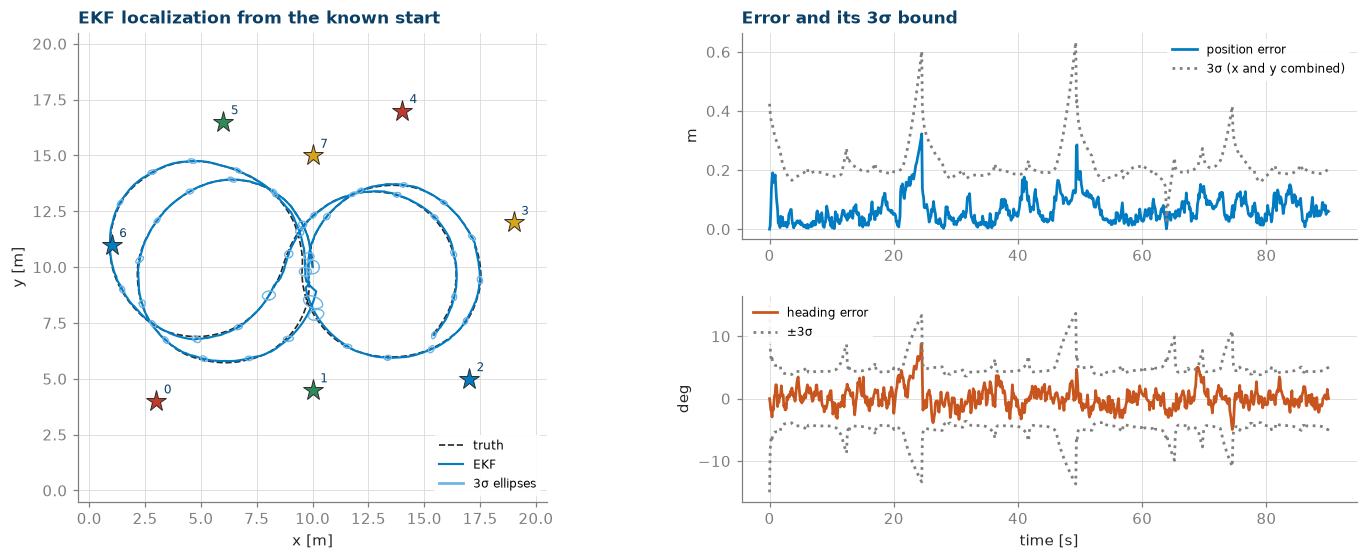

Self-check 1.2: passed.


In [7]:
# Self-check 1.2: (a) a reading across the ±180 deg seam; (b) the run from the known start
try:
    m = LANDMARKS[0]                                     # landmark (3, 4); robot 3 m to its right, facing +x
    mu_bar = np.array([6.0, 4.0 + 0.05, np.radians(1.0)])
    zt = h(mu_bar, m)                                    # predicted bearing close to +180 deg ...
    z = np.array([zt[0], wrap_angle(zt[1] + np.radians(2.0))])   # ... and a reading 2 deg further: about -178 deg
    mu_a, S_a = ekf_correct(mu_bar, np.diag([0.04, 0.04, 0.01]), z, m)
    jump = np.hypot(*(np.asarray(mu_a)[:2] - mu_bar[:2]))
    seam_ok = jump < 0.2 and abs(wrap_angle(mu_a[2] - mu_bar[2])) < np.radians(5) and abs(mu_a[2]) <= np.pi
    print(f'(a) reading across the seam: the mean moves {jump:.3f} m and {np.degrees(wrap_angle(mu_a[2] - mu_bar[2])):.2f} deg')

    Sigma0 = np.diag([0.01, 0.01, np.radians(5) ** 2])
    t0 = time.time(); MU_E, SIG_E = run_ekf(DATA, X0, Sigma0); EKF_MS = 1000 * (time.time() - t0) / len(DATA['u'])
    pe = np.hypot(*(DATA['x'][:, :2] - MU_E[:, :2]).T)
    inside = np.mean(pe < 3 * np.sqrt(SIG_E[:, 0, 0] + SIG_E[:, 1, 1]))
    print(f'(b) run from the known start: position RMSE {np.sqrt(np.mean(pe ** 2)):.3f} m, '
          f'error inside its 3-sigma bound in {100 * inside:.1f} % of the steps')
    plot_ekf(DATA, MU_E, SIG_E, 'EKF localization from the known start')
    ok = seam_ok and np.sqrt(np.mean(pe ** 2)) < 0.25 and inside > 0.95
    print('Self-check 1.2:', 'passed.' if ok else 'not yet: ' + (
        'wrap the bearing of the innovation and the heading of the new mean.' if not seam_ok else
        'the run does not track; check K, the innovation and (I - K H).'))
except NotImplementedError as e:
    print(e)

The ellipses shrink as soon as two landmarks are in view and grow along the stretches where only one, or
none, is: the filter *knows* how much it knows. The bound in the middle plot is 3σ of the position; the error
stays below it nearly all the time, which is what a consistent filter should do (slide *Is the filter honest?*).

### Watch it

The same run as an animation, one frame every 2 s: the true robot (orange outline) and the EKF's estimate (blue),
its 3σ ellipse, and the readings of the moment, coloured by landmark colour.

In [8]:
#@title Provided: animation of the EKF run
try:
    display(animate_ekf(DATA, MU_E, SIG_E, title='EKF, known start'))
except NameError:
    print('Finish 1.2 first.')

## 1.3 · Experiments — what the filter believes

A Kalman filter is only as good as what it is told about the noise. The cell below the next one reruns the EKF with
settings you choose. Two of them change what the filter **believes**, two change the **real** robot and sensor
(the data are simulated again), and two set the **initial guess**:

| Setting | Default | Meaning |
|---|---|---|
| `Q_SCALE` | 1 | multiplies the sensor covariance $Q$ the filter believes. Below 1: it trusts the sensor more than it should |
| `M_SCALE` | 1 | multiplies the motion covariance $M$ the filter believes. Below 1: it trusts the odometry more than it should |
| `SENSOR_NOISE` | 1 | multiplies the **real** sensor noise (σ_r and σ_φ). The filter is not told unless you also change `Q_SCALE` (by the square) |
| `SENSOR_RANGE` | 6.0 | the **real** sensor range [m] |
| `START_ERROR` | (0, 0, 0) | error of the initial guess: dx [m], dy [m], dθ [deg] |
| `START_SIGMA` | (0.1, 0.1, 5) | standard deviations the filter believes for the initial guess: x [m], y [m], θ [deg] |

Each run prints the position RMSE, the error at the end, how often the error is inside the 3σ bound, the mean NEES
(about 3 for an honest filter, slide *Is the filter honest?*), and how many readings the data association used,
rejected at the gate, or gave to the wrong landmark. Then it shows the animation and the plots.

Do **at least two** of these experiments. Before each run, write down what you expect; then run it and compare.

1. **Over-confident sensor.** `Q_SCALE = 0.01` (the filter thinks the sensor is ten times more precise than it is).
   Then the opposite, `Q_SCALE = 100`. Watch the ellipse, the readings rejected and the NEES.
2. **Over-confident motion model.** `M_SCALE = 0.01`. Then `M_SCALE = 100`. Which one gets lost, and why does the
   gate matter here?
3. **A wrong start.** `START_ERROR = (2, -2, 30)` with an honest `START_SIGMA = (2, 2, 40)`; then the same error
   with the default, over-confident `START_SIGMA = (0.1, 0.1, 5)`. How long does each take to find the robot, if it
   does?
4. **A worse sensor, and whether you tell the filter.** `SENSOR_NOISE = 3` with `Q_SCALE = 1`; then
   `SENSOR_NOISE = 3` with `Q_SCALE = 9`.
5. **A short-sighted sensor.** `SENSOR_RANGE = 3`. Where along the path does the ellipse grow, and does the error
   stay inside it?

Reset every setting to its default before the next experiment, so that you change one thing at a time.

In [9]:
#@title Provided: run_experiment (run it once, then use the next cell)
def run_experiment(Q_SCALE=1.0, M_SCALE=1.0, SENSOR_NOISE=1.0, SENSOR_RANGE=MAX_RANGE,
                   START_ERROR=(0.0, 0.0, 0.0), START_SIGMA=(0.1, 0.1, 5.0), animate=True):
    data = simulate(SEED + 22, sensor_scale=SENSOR_NOISE, max_range=SENSOR_RANGE)
    err = np.array(START_ERROR, float); err[2] = np.radians(err[2])
    sd = np.array(START_SIGMA, float); sd[2] = np.radians(sd[2])
    mus, Sig = run_ekf(data, X0 + err, np.diag(sd ** 2), q_scale=Q_SCALE, m_scale=M_SCALE)
    e = data['x'] - mus; e[:, 2] = wrap_angle(e[:, 2])
    pe = np.hypot(e[:, 0], e[:, 1])
    nees = np.mean([e[k] @ np.linalg.solve(Sig[k], e[k]) for k in range(len(e))])
    inside = np.mean(pe < 3 * np.sqrt(Sig[:, 0, 0] + Sig[:, 1, 1]))
    found = next((data['t'][k] for k in range(len(pe)) if (pe[k:] < 0.5).all()), None)
    s = EKF_STATS
    print(f'Q_SCALE={Q_SCALE}, M_SCALE={M_SCALE}, SENSOR_NOISE={SENSOR_NOISE}, SENSOR_RANGE={SENSOR_RANGE}, '
          f'START_ERROR={START_ERROR}, START_SIGMA={START_SIGMA}')
    print(f'  position RMSE {np.sqrt(np.mean(pe ** 2)):.2f} m · error at the end {pe[-1]:.2f} m · '
          f'inside 3σ {100 * inside:.0f} % of the time · mean NEES {nees:.1f} (honest: about 3)')
    print(f'  readings: {s["used"]} used, {s["rejected"]} rejected by the gate, {s["wrong"]} given to the wrong landmark · '
          + (f'error below 0.5 m for good from t = {found:.0f} s' if found is not None else 'error never settles below 0.5 m'))
    if animate:
        display(animate_ekf(data, mus, Sig, title='Experiment'))
    plot_ekf(data, mus, Sig, 'Experiment')


Over-confident sensor
Prediction: Small ellipses and high NEES; the tight gate rejects more real readings.
Q_SCALE=0.01, M_SCALE=1.0, SENSOR_NOISE=1.0, SENSOR_RANGE=6.0, START_ERROR=(0.0, 0.0, 0.0), START_SIGMA=(0.1, 0.1, 5.0)
  position RMSE 0.51 m · error at the end 0.26 m · inside 3σ 51 % of the time · mean NEES 73.1 (honest: about 3)
  readings: 157 used, 712 rejected by the gate, 0 given to the wrong landmark · error below 0.5 m for good from t = 70 s


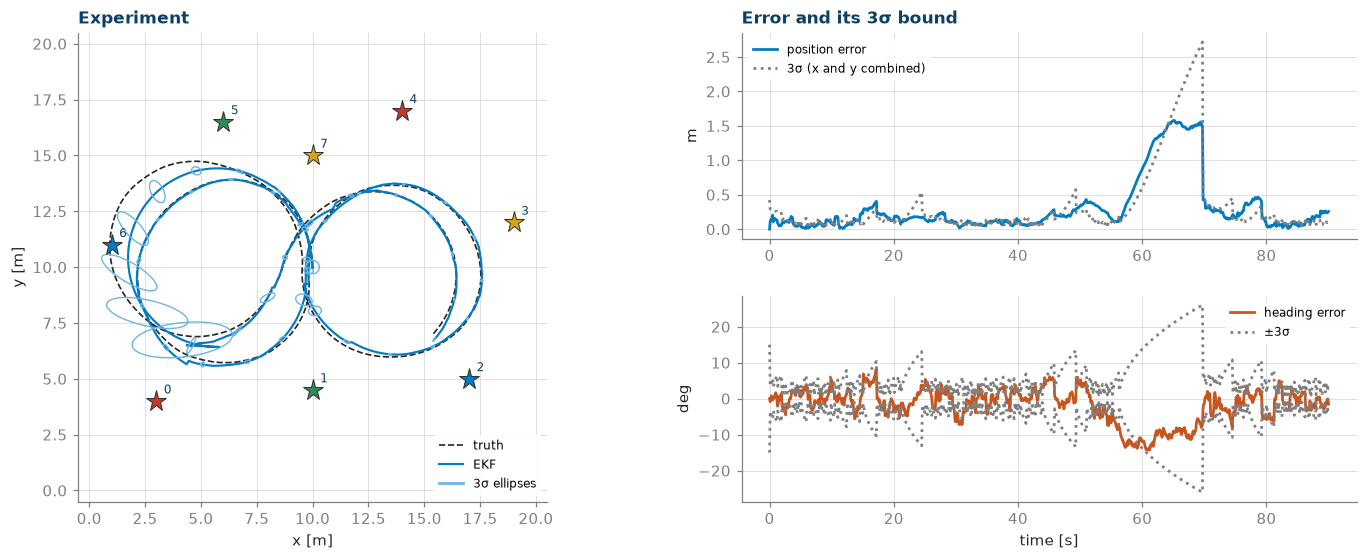


Under-confident sensor
Prediction: Larger ellipses and low NEES; observations correct the motion less strongly.
Q_SCALE=100, M_SCALE=1.0, SENSOR_NOISE=1.0, SENSOR_RANGE=6.0, START_ERROR=(0.0, 0.0, 0.0), START_SIGMA=(0.1, 0.1, 5.0)
  position RMSE 0.12 m · error at the end 0.23 m · inside 3σ 100 % of the time · mean NEES 1.1 (honest: about 3)
  readings: 869 used, 0 rejected by the gate, 0 given to the wrong landmark · error below 0.5 m for good from t = 0 s


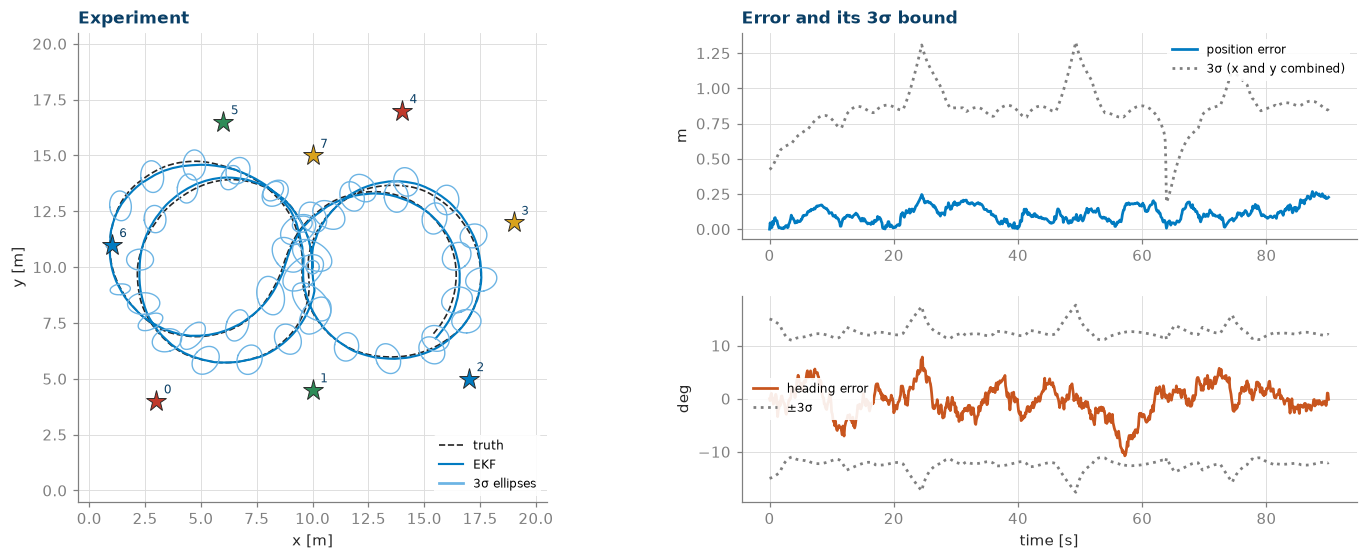


Over-confident motion
Prediction: Covariance grows too slowly; true readings may be gated out and tracking may fail.
Q_SCALE=1.0, M_SCALE=0.01, SENSOR_NOISE=1.0, SENSOR_RANGE=6.0, START_ERROR=(0.0, 0.0, 0.0), START_SIGMA=(0.1, 0.1, 5.0)
  position RMSE 0.55 m · error at the end 0.22 m · inside 3σ 34 % of the time · mean NEES 175.5 (honest: about 3)
  readings: 690 used, 179 rejected by the gate, 0 given to the wrong landmark · error below 0.5 m for good from t = 77 s


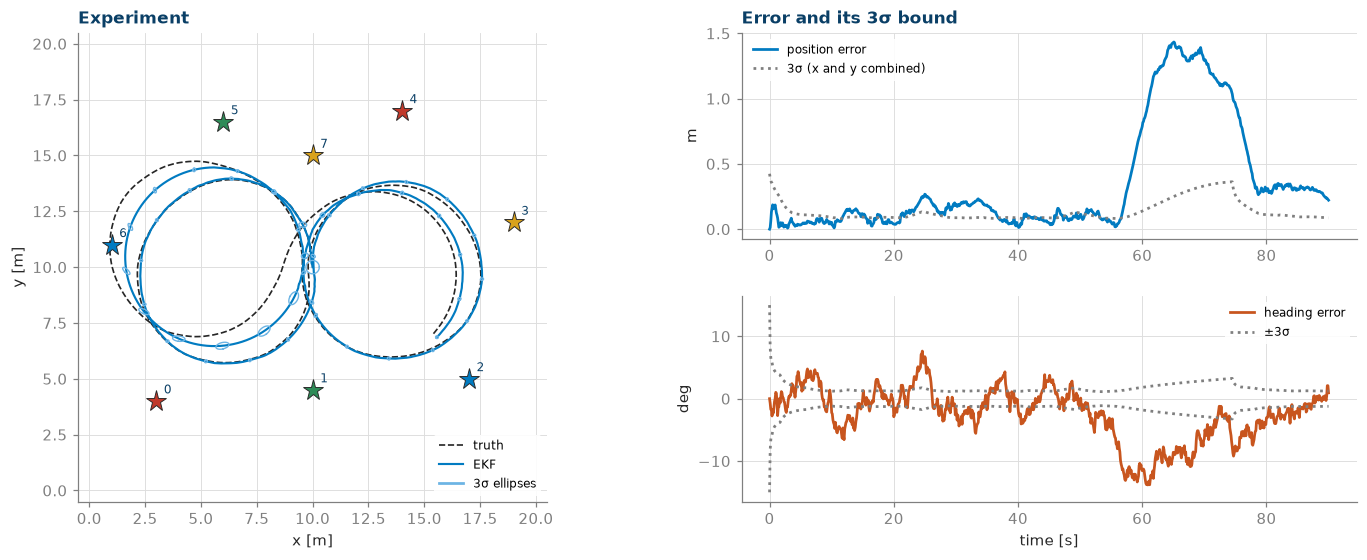


Under-confident motion
Prediction: Larger uncertainty admits more readings and gives measurements more influence.
Q_SCALE=1.0, M_SCALE=100, SENSOR_NOISE=1.0, SENSOR_RANGE=6.0, START_ERROR=(0.0, 0.0, 0.0), START_SIGMA=(0.1, 0.1, 5.0)
  position RMSE 0.17 m · error at the end 0.06 m · inside 3σ 100 % of the time · mean NEES 2.0 (honest: about 3)
  readings: 869 used, 0 rejected by the gate, 0 given to the wrong landmark · error below 0.5 m for good from t = 0 s


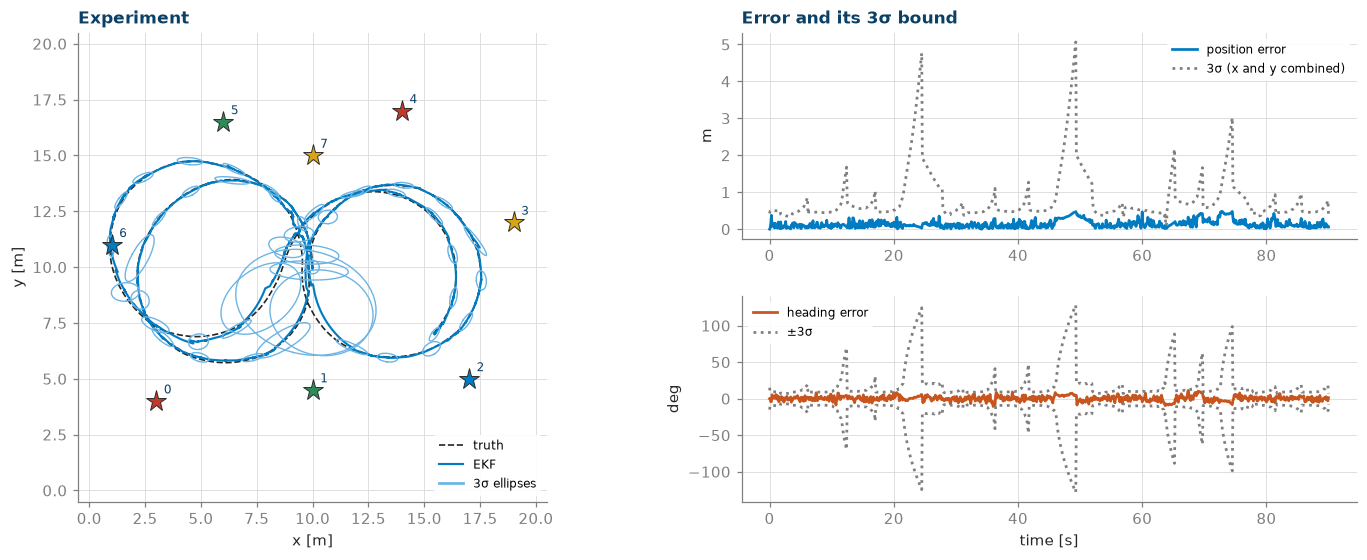


Wrong start, honest uncertainty
Prediction: The broad prior includes the truth, so the estimate should recover quickly.
Q_SCALE=1.0, M_SCALE=1.0, SENSOR_NOISE=1.0, SENSOR_RANGE=6.0, START_ERROR=(2, -2, 30), START_SIGMA=(2, 2, 40)
  position RMSE 0.17 m · error at the end 0.06 m · inside 3σ 100 % of the time · mean NEES 3.1 (honest: about 3)
  readings: 857 used, 12 rejected by the gate, 0 given to the wrong landmark · error below 0.5 m for good from t = 2 s


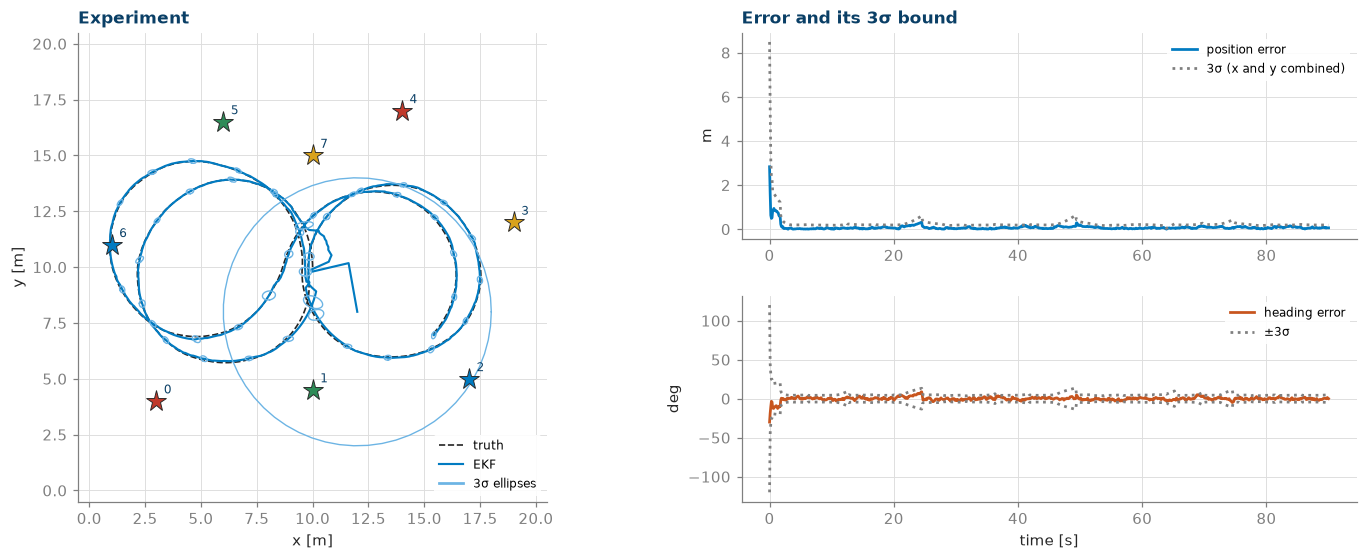


Wrong start, over-confident uncertainty
Prediction: The narrow incorrect prior rejects useful readings and may never recover.
Q_SCALE=1.0, M_SCALE=1.0, SENSOR_NOISE=1.0, SENSOR_RANGE=6.0, START_ERROR=(2, -2, 30), START_SIGMA=(0.1, 0.1, 5.0)
  position RMSE 4.27 m · error at the end 6.48 m · inside 3σ 5 % of the time · mean NEES 108.0 (honest: about 3)
  readings: 137 used, 732 rejected by the gate, 0 given to the wrong landmark · error never settles below 0.5 m


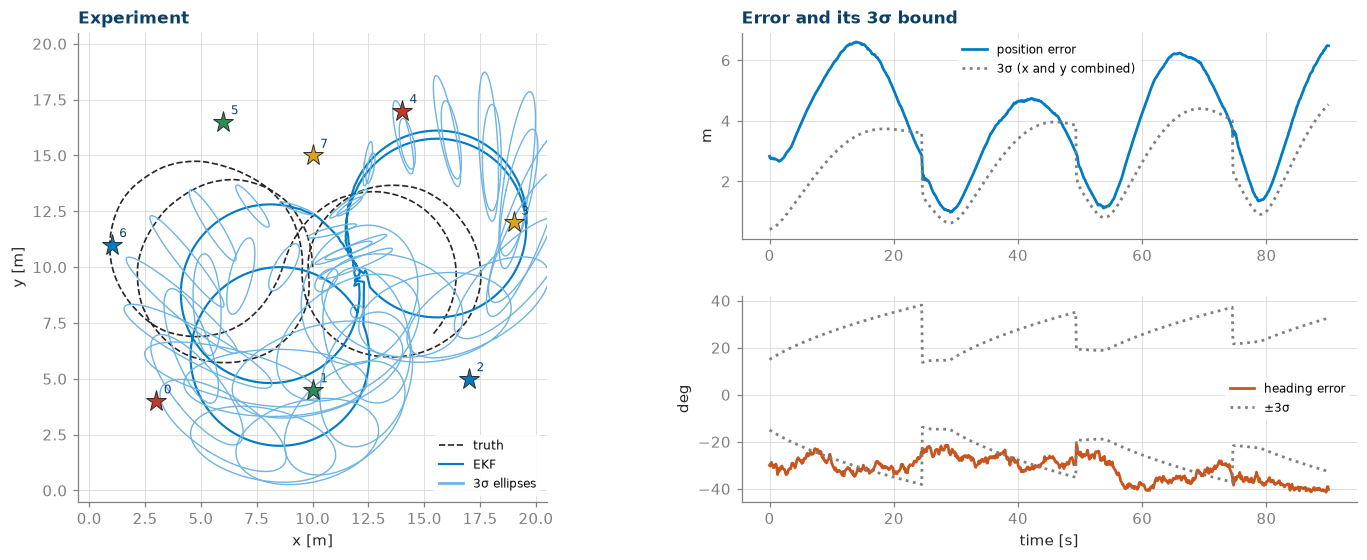


Worse sensor, unreported
Prediction: The gate rejects more observations and NEES rises above the consistent scale.
Q_SCALE=1.0, M_SCALE=1.0, SENSOR_NOISE=3, SENSOR_RANGE=6.0, START_ERROR=(0.0, 0.0, 0.0), START_SIGMA=(0.1, 0.1, 5.0)
  position RMSE 0.37 m · error at the end 0.49 m · inside 3σ 47 % of the time · mean NEES 36.9 (honest: about 3)
  readings: 333 used, 536 rejected by the gate, 0 given to the wrong landmark · error below 0.5 m for good from t = 90 s


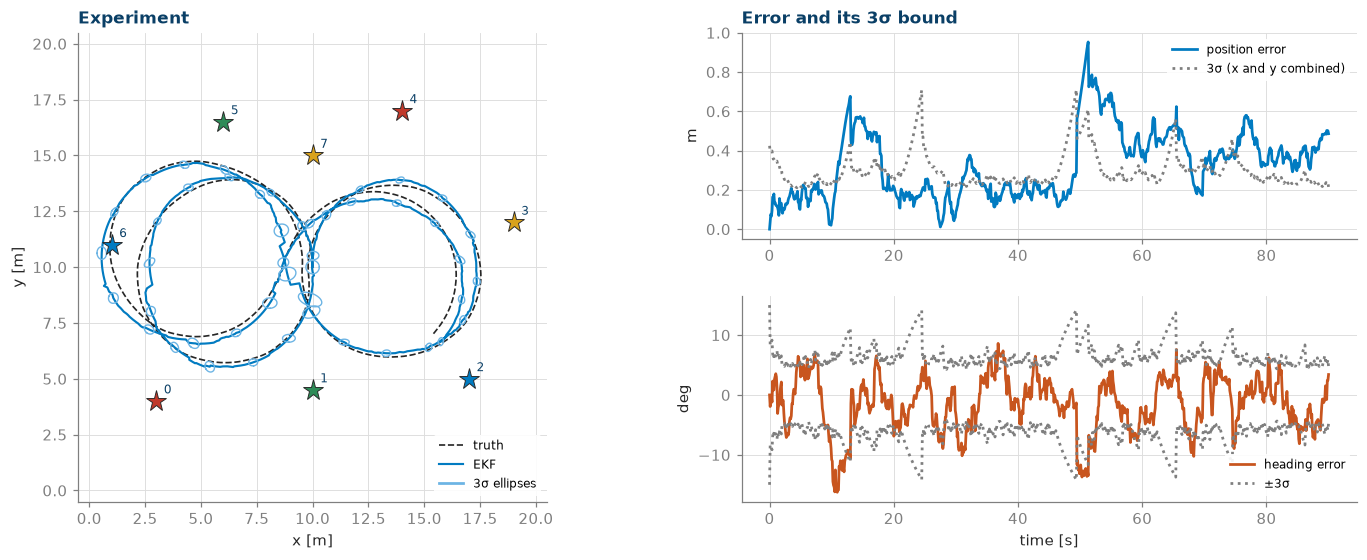


Worse sensor, reported
Prediction: Matching the covariance restores better consistency, with less precise localization.
Q_SCALE=9, M_SCALE=1.0, SENSOR_NOISE=3, SENSOR_RANGE=6.0, START_ERROR=(0.0, 0.0, 0.0), START_SIGMA=(0.1, 0.1, 5.0)
  position RMSE 0.13 m · error at the end 0.21 m · inside 3σ 100 % of the time · mean NEES 2.7 (honest: about 3)
  readings: 859 used, 10 rejected by the gate, 0 given to the wrong landmark · error below 0.5 m for good from t = 0 s


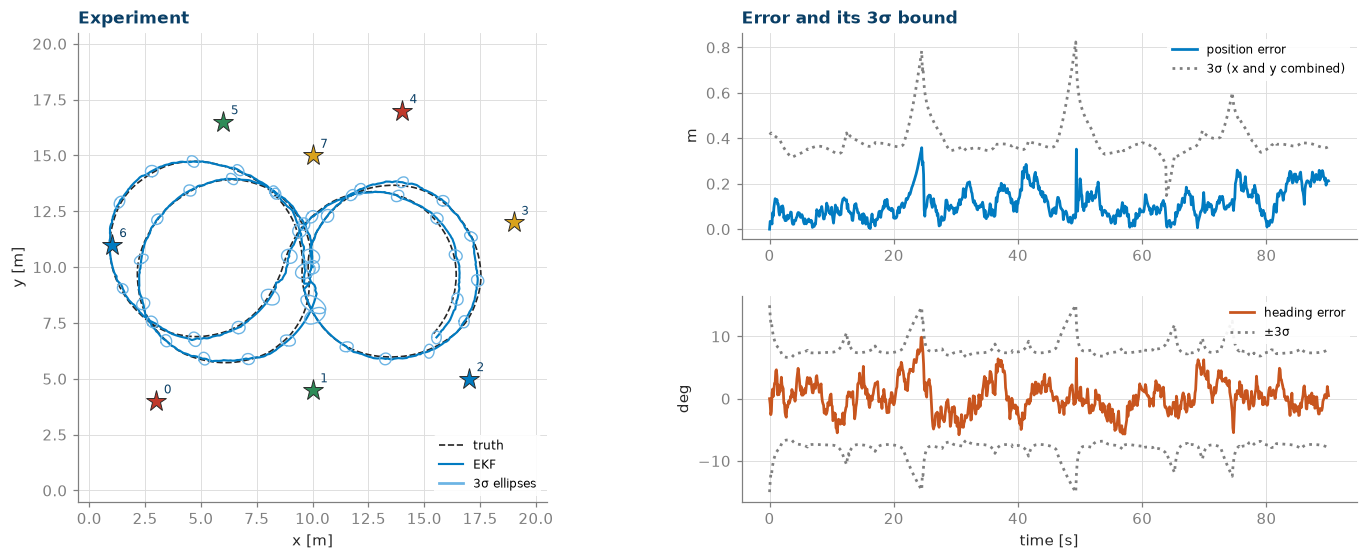


Short-sighted sensor
Prediction: Longer gaps without landmarks cause larger ellipses and position errors.
Q_SCALE=1.0, M_SCALE=1.0, SENSOR_NOISE=1.0, SENSOR_RANGE=3, START_ERROR=(0.0, 0.0, 0.0), START_SIGMA=(0.1, 0.1, 5.0)
  position RMSE 0.34 m · error at the end 0.11 m · inside 3σ 100 % of the time · mean NEES 2.7 (honest: about 3)
  readings: 248 used, 0 rejected by the gate, 0 given to the wrong landmark · error below 0.5 m for good from t = 66 s


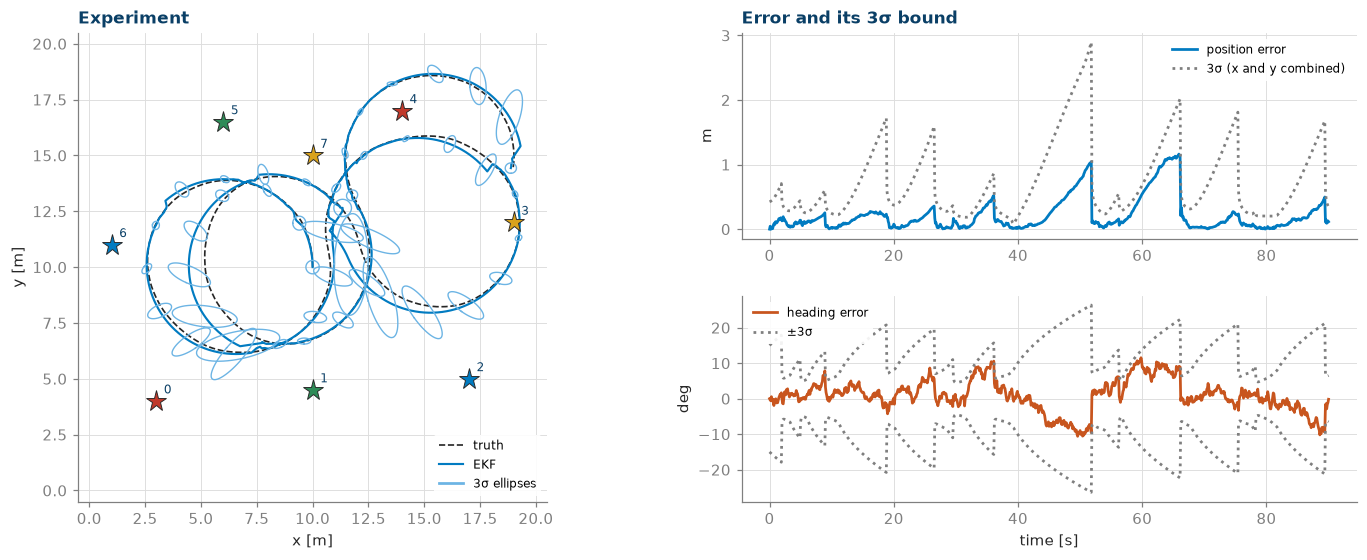

In [10]:
# Each call starts from the defaults and changes only the stated settings.
# Print each prediction BEFORE running the corresponding experiment.
EXPERIMENTS = [
    ('Over-confident sensor', dict(Q_SCALE=0.01),
     'Small ellipses and high NEES; the tight gate rejects more real readings.'),
    ('Under-confident sensor', dict(Q_SCALE=100),
     'Larger ellipses and low NEES; observations correct the motion less strongly.'),
    ('Over-confident motion', dict(M_SCALE=0.01),
     'Covariance grows too slowly; true readings may be gated out and tracking may fail.'),
    ('Under-confident motion', dict(M_SCALE=100),
     'Larger uncertainty admits more readings and gives measurements more influence.'),
    ('Wrong start, honest uncertainty',
     dict(START_ERROR=(2, -2, 30), START_SIGMA=(2, 2, 40)),
     'The broad prior includes the truth, so the estimate should recover quickly.'),
    ('Wrong start, over-confident uncertainty', dict(START_ERROR=(2, -2, 30)),
     'The narrow incorrect prior rejects useful readings and may never recover.'),
    ('Worse sensor, unreported', dict(SENSOR_NOISE=3),
     'The gate rejects more observations and NEES rises above the consistent scale.'),
    ('Worse sensor, reported', dict(SENSOR_NOISE=3, Q_SCALE=9),
     'Matching the covariance restores better consistency, with less precise localization.'),
    ('Short-sighted sensor', dict(SENSOR_RANGE=3),
     'Longer gaps without landmarks cause larger ellipses and position errors.')]
EXPERIMENT_RESULTS = []
for name, settings, prediction in EXPERIMENTS:
    print(f'\n{name}\nPrediction: {prediction}')
    run_experiment(**settings, animate=False)
    # Recompute numeric summaries for the written table without changing provided helpers.
    d = simulate(SEED + 22, sensor_scale=settings.get('SENSOR_NOISE', 1),
                 max_range=settings.get('SENSOR_RANGE', MAX_RANGE))
    err = np.array(settings.get('START_ERROR', (0, 0, 0)), float)
    err[2] = np.radians(err[2])
    sd = np.array(settings.get('START_SIGMA', (0.1, 0.1, 5)), float)
    sd[2] = np.radians(sd[2])
    mu, sig = run_ekf(d, X0 + err, np.diag(sd ** 2),
                      q_scale=settings.get('Q_SCALE', 1), m_scale=settings.get('M_SCALE', 1))
    e = d['x'] - mu
    e[:, 2] = wrap_angle(e[:, 2])
    pe = np.linalg.norm(e[:, :2], axis=1)
    found = next((float(d['t'][k]) for k in range(len(pe)) if (pe[k:] < 0.5).all()), None)
    EXPERIMENT_RESULTS.append(dict(name=name, settings=settings, prediction=prediction,
        rmse=float(np.sqrt(np.mean(pe ** 2))), final=float(pe[-1]),
        inside=float(np.mean(pe < 3 * np.sqrt(sig[:, 0, 0] + sig[:, 1, 1]))),
        nees=float(np.mean([ei @ np.linalg.solve(si, ei) for ei, si in zip(e, sig)])),
        found=found, stats=EKF_STATS.copy()))

**Answer 1.3.** All settings not listed were reset to their defaults before each run. Predictions were recorded before execution in the preceding cell.

| Experiment | Setting | Expected | What happened |
|---|---|---|---|
| Over-confident sensor | `Q_SCALE=0.01` | Small ellipses and high NEES; the tight gate rejects more real readings. | RMSE 0.508 m; final 0.257 m; inside 3σ 51.1%; NEES 73.1; readings 157 used / 712 rejected / 0 wrong; settled below 0.5 m from 69.8 s. |
| Under-confident sensor | `Q_SCALE=100` | Larger ellipses and low NEES; observations correct the motion less strongly. | RMSE 0.124 m; final 0.227 m; inside 3σ 100.0%; NEES 1.1; readings 869 used / 0 rejected / 0 wrong; settled below 0.5 m from 0.0 s. |
| Over-confident motion | `M_SCALE=0.01` | Covariance grows too slowly; true readings may be gated out and tracking may fail. | RMSE 0.546 m; final 0.222 m; inside 3σ 34.4%; NEES 175.5; readings 690 used / 179 rejected / 0 wrong; settled below 0.5 m from 77.4 s. |
| Under-confident motion | `M_SCALE=100` | Larger uncertainty admits more readings and gives measurements more influence. | RMSE 0.175 m; final 0.057 m; inside 3σ 100.0%; NEES 2.0; readings 869 used / 0 rejected / 0 wrong; settled below 0.5 m from 0.0 s. |
| Wrong start, honest uncertainty | `START_ERROR=[2, -2, 30]`, `START_SIGMA=[2, 2, 40]` | The broad prior includes the truth, so the estimate should recover quickly. | RMSE 0.168 m; final 0.060 m; inside 3σ 100.0%; NEES 3.1; readings 857 used / 12 rejected / 0 wrong; settled below 0.5 m from 1.8 s. |
| Wrong start, over-confident uncertainty | `START_ERROR=[2, -2, 30]` | The narrow incorrect prior rejects useful readings and may never recover. | RMSE 4.274 m; final 6.476 m; inside 3σ 5.3%; NEES 108.0; readings 137 used / 732 rejected / 0 wrong; never settled below 0.5 m. |
| Worse sensor, unreported | `SENSOR_NOISE=3` | The gate rejects more observations and NEES rises above the consistent scale. | RMSE 0.371 m; final 0.486 m; inside 3σ 47.3%; NEES 36.9; readings 333 used / 536 rejected / 0 wrong; settled below 0.5 m from 90.0 s. |
| Worse sensor, reported | `SENSOR_NOISE=3`, `Q_SCALE=9` | Matching the covariance restores better consistency, with less precise localization. | RMSE 0.130 m; final 0.212 m; inside 3σ 100.0%; NEES 2.7; readings 859 used / 10 rejected / 0 wrong; settled below 0.5 m from 0.0 s. |
| Short-sighted sensor | `SENSOR_RANGE=3` | Longer gaps without landmarks cause larger ellipses and position errors. | RMSE 0.340 m; final 0.115 m; inside 3σ 100.0%; NEES 2.7; readings 248 used / 0 rejected / 0 wrong; settled below 0.5 m from 66.2 s. |

With `Q_SCALE=0.01`, NEES rose to 73.1 and 712 readings were rejected, matching the prediction that over-trusting the sensor makes the gate too selective. With `Q_SCALE=100`, no readings were rejected, the bound covered every step, and NEES fell to 1.1, showing conservative uncertainty.

With `M_SCALE=0.01`, the filter temporarily lost accurate tracking (RMSE 0.546 m, NEES 175.5), but recovered to stay within 0.5 m at 77.4 s; the narrow gate rejected 179 readings that could otherwise correct drift. With `M_SCALE=100`, none were rejected and tracking stayed within 0.5 m throughout, although extra trust in noisy readings increased RMSE to 0.175 m.

The honest wrong-start prior recovered permanently below 0.5 m in 1.8 s, with NEES 3.1. The same mean with a narrow prior never settled below 0.5 m, rejected 732 readings, and finished 6.476 m away, as predicted.

Tripling the real sensor noise without telling the filter gave RMSE 0.371 m, NEES 36.9, and 536 rejected readings. Setting `Q_SCALE=9` matched the variance increase and improved these to 0.130 m, 2.7, and 10, respectively.

With a 3 m range, the ellipse grows along the portions of the path without readings, especially 39.4–51.8 s and 56.8–66.1 s (also 11.2–18.8 s and 81.8–89.4 s). RMSE increased to 0.340 m, but the position error remained inside the plotted 3σ bound at every step, consistent with the filter acknowledging its uncertainty.

A filter is **wrong** when its estimate differs substantially from the true pose; it is **over-confident** when its stated uncertainty is too small for its actual errors, which can also prevent correction through gating.

## 1.4 · Break it — the kidnapping

In `DATA_K` the robot drives the same figure of eight, but at t = 40 s it is picked up and put down at the
mirror pose through the centre of the arena, facing the other way: (20 − x, 20 − y, θ + 180°). No command
explains the jump. Run the same EKF.

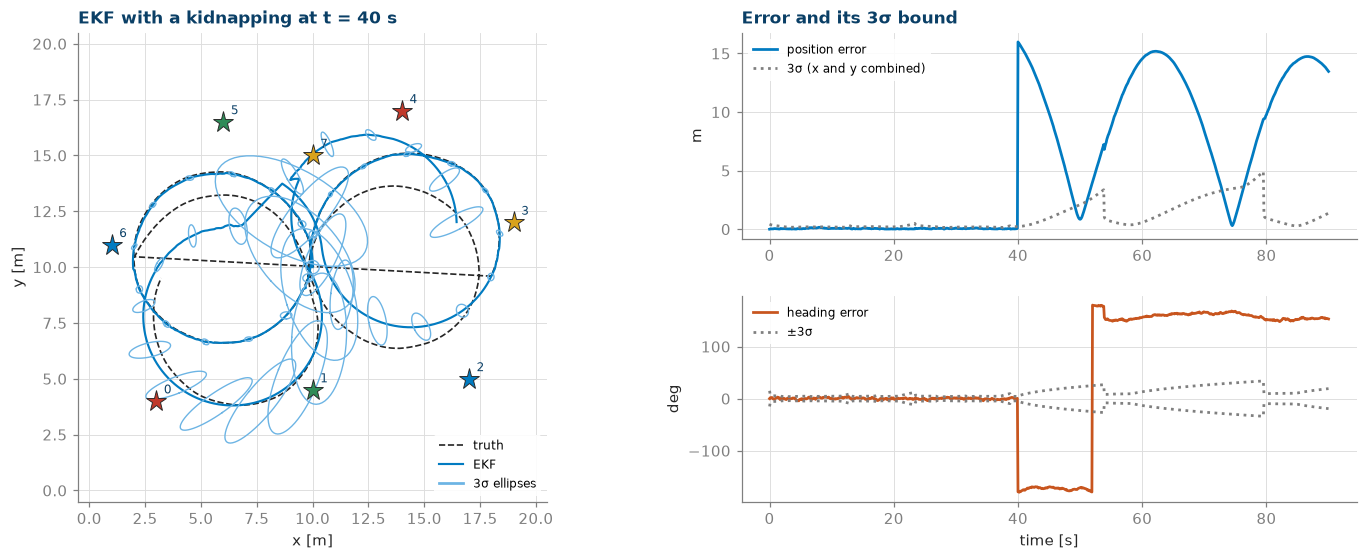

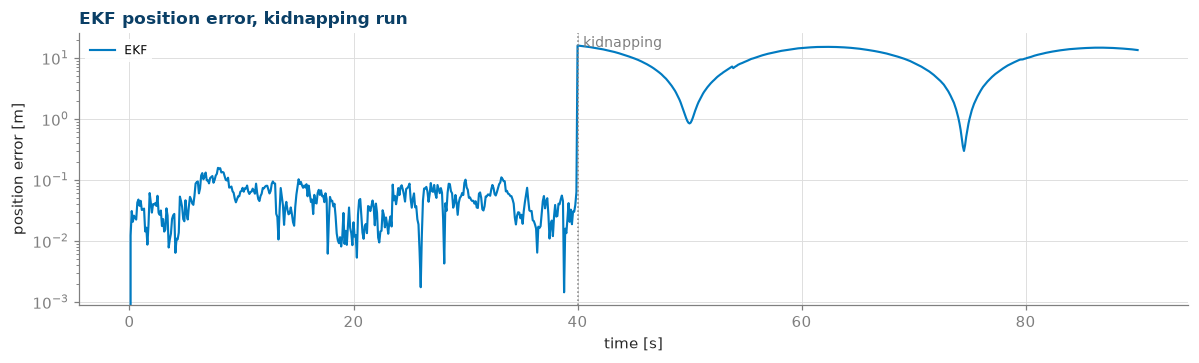

position error just before the kidnapping 0.06 m, at the end 13.46 m


In [11]:
#@title Provided: EKF on the kidnapping data
try:
    MU_K, SIG_K = run_ekf(DATA_K, X0, np.diag([0.01, 0.01, np.radians(5) ** 2]))
    plot_ekf(DATA_K, MU_K, SIG_K, 'EKF with a kidnapping at t = 40 s')
    plot_errors(DATA_K, [(MU_K, 'EKF', BLUE)], 'EKF position error, kidnapping run')
    k = int(KIDNAP_T / DT)
    print(f'position error just before the kidnapping {np.hypot(*(DATA_K["x"][k - 1, :2] - MU_K[k - 1, :2])):.2f} m, '
          f'at the end {np.hypot(*(DATA_K["x"][-1, :2] - MU_K[-1, :2])):.2f} m')
except NotImplementedError as e:
    print(e)

**Answer 1.4.** The position error jumps from 0.063 m immediately before the kidnapping to 15.981 m at t = 40 s, while the plotted combined-position 3σ radius is only 0.215 m: the prediction adds ordinary motion noise and cannot anticipate a teleportation. Most readings compatible with the new pose are far outside the old Gaussian's Mahalanobis gate, so the EKF rejects the evidence needed to move there and finishes 13.463 m away without recovering. To consider the truth its covariance would need to expand enough to cover the distant pose and approximately 180° heading change; representing the old and new hypotheses simultaneously would require more than one local Gaussian.

---
# Part 2 · Monte Carlo localization

A particle filter represents the belief by $M$ poses (slides *The particle filter*, *Monte Carlo localization*).
At every step the provided `run_mcl`:

1. moves every particle with its own noisy copy of the command (`sample_motion`: the velocity model, *sampled*);
2. weights every particle by how well it explains the readings: $w^{[m]} \propto p(z \mid x^{[m]})$. **This is
   your function**;
3. resamples $M$ particles in proportion to the weights (`low_variance_resample`).

No Jacobians, no Gaussians, no data association: each particle checks the readings against its own pose.

## 2.1 · TODO — the likelihood of a particle

For one reading $z = (r, \phi, c)$ and one particle $x$: the reading came from one of the two landmarks of colour
$c$, and we do not know which, so its likelihood is the **sum** of the two Gaussians:
$$p(z \mid x) \;\propto\; \sum_{m:\ \text{colour}(m) = c}
\exp\!\Big(-\tfrac12\Big(\frac{r - \hat r_m}{\sigma_r}\Big)^2 - \tfrac12\Big(\frac{\operatorname{wrap}(\phi - \hat\phi_m)}{\sigma_\phi}\Big)^2\Big),
\qquad (\hat r_m, \hat\phi_m) = h(x, m).$$
The readings of one step are independent given the pose, so their likelihoods multiply: the **logarithms add**.

Return the **log-likelihood** of every particle, an array of shape `(M,)`. Work in logarithms (the products of
small numbers underflow), and use `h(particles, m)`, which already works on all $M$ particles at once (it returns
an `(M, 2)` array). Constant factors do not matter: the weights are normalised afterwards, so you may drop
$1/(2\pi\sigma_r\sigma_\phi)$ and the ½ of the "one of two". `np.logaddexp(a, b)` computes
$\log(e^a + e^b)$ safely. Landmarks of colour `c`: `LANDMARKS[COLOURS == c]`.

In [12]:
def log_likelihood(particles, z, sigma_r=SIGMA_R, sigma_phi=SIGMA_PHI):
    """Sum log mixture likelihoods; marginalize the unknown landmark identity."""
    logw = np.zeros(len(particles), dtype=float)
    for r, phi, colour in z:
        # log(0) starts the sum over possible landmarks of this colour.
        reading_logw = np.full(len(particles), -np.inf)
        for landmark in LANDMARKS[COLOURS == int(colour)]:
            predicted = h(particles, landmark)
            dr = (r - predicted[:, 0]) / sigma_r
            dphi = wrap_angle(phi - predicted[:, 1]) / sigma_phi
            reading_logw = np.logaddexp(reading_logw, -0.5 * (dr ** 2 + dphi ** 2))
        logw += reading_logw
    return logw

In [13]:
# Self-check 2.1: six particles, three readings, fixed noise; only differences between particles are compared
try:
    P_test = np.array([[10.0, 10.0, 1.5708], [9.6, 10.3, 1.45], [10.5, 9.4, 1.75], [12.0, 12.0, 0.4], [4.0, 6.0, -1.0], [10.2, 10.1, -1.5]])
    z_test = np.array([[5.1, -0.62, 3.0], [5.0, 0.0, 3.0], [4.9, 0.12, 1.0]])
    ll = np.asarray(log_likelihood(P_test, z_test, 0.15, 0.05), float)
    ref = np.array([0.0, 18.949, -79.4585, -863.3334, -3456.3567, -1986.6719])
    print('your log-likelihoods minus that of particle 0:', np.round(ll - ll[0], 2))
    print('expected:                                     ', np.round(ref, 2))
    shape_ok = ll.shape == (6,)
    ok = shape_ok and np.allclose(ll - ll[0], ref, atol=1e-3 * np.maximum(1, np.abs(ref)))
    big = np.asarray(log_likelihood(uniform_particles(5000, np.random.default_rng(3)), DATA['z'][100]), float)
    ok = ok and big.shape == (5000,) and np.all(np.isfinite(big))
    print('Self-check 2.1:', 'passed.' if ok else 'not yet: ' + (
        'return one value per particle, shape (M,).' if not shape_ok else
        'check the sum over the two landmarks of the colour (logaddexp), the wrapped bearing, and that the '
        'logarithms of the readings add.'))
except NotImplementedError as e:
    print(e)

your log-likelihoods minus that of particle 0: [    0.      18.95   -79.46  -863.33 -3456.36 -1986.67]
expected:                                      [    0.      18.95   -79.46  -863.33 -3456.36 -1986.67]
Self-check 2.1: passed.


## 2.2 · Read — low-variance resampling

The provided `low_variance_resample` (Thrun et al., Table 4.4; slide *Low-variance resampling*) is three lines:

```python
pointers = g_.uniform(0, 1 / M) + np.arange(M) / M      # one random number, M equally spaced pointers
idx = np.searchsorted(np.cumsum(w), pointers)            # which particle each pointer falls on
return particles[np.minimum(idx, M - 1)]
```

**Answer 2.2.** (a) If all the weights are equal, which particles come out? (b) Why is that a good property
compared with drawing $M$ independent samples with `g_.choice(M, M, p=w)`?

(a) With equal weights, each original particle appears exactly once, in its original order (apart from measure-zero boundary effects in floating-point arithmetic).  
(b) Independent multinomial sampling can duplicate some particles and omit others even when all are equally plausible, whereas low-variance resampling preserves the entire cloud in this case and introduces less unnecessary sampling noise and loss of diversity.

### MY answer:

We have either ordinary random sampling or LOW-VARIANCE resampling. The difference is easy. Lets say we have 4 positions A, B, C, D with the SAME weight. Now the low variance one will resample each location once. The ORDINARY random sampling might instead pick A, B, D, D and WOOPS we lost C. Not good. Like that we might have lost a particle close to the true position if it was C. 

## 2.3 · Global localization

Now the filter starts from **nothing**: 3000 particles spread uniformly over the arena with random headings. The
robot itself does not know where it is. Watch the animation, then the snapshots.

One setting needs explaining: `inflate=3` makes the filter *assume* a sensor three times noisier than the real
one. With few particles near the truth at the start, an exact (very peaked) likelihood would give almost all the
weight to whichever particle happens to be closest and wipe out the rest at the first resampling. A flatter
likelihood keeps more hypotheses alive while the cloud converges (slide *How many particles?*).

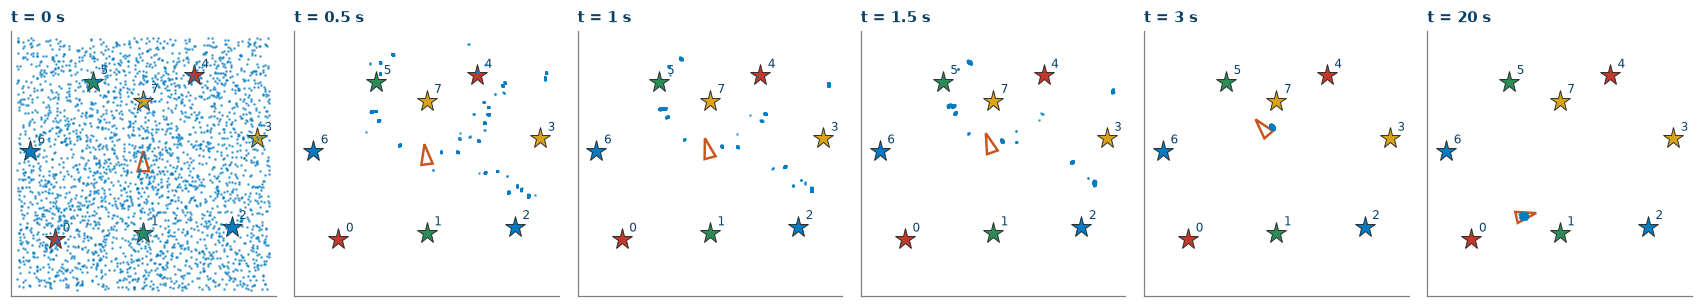

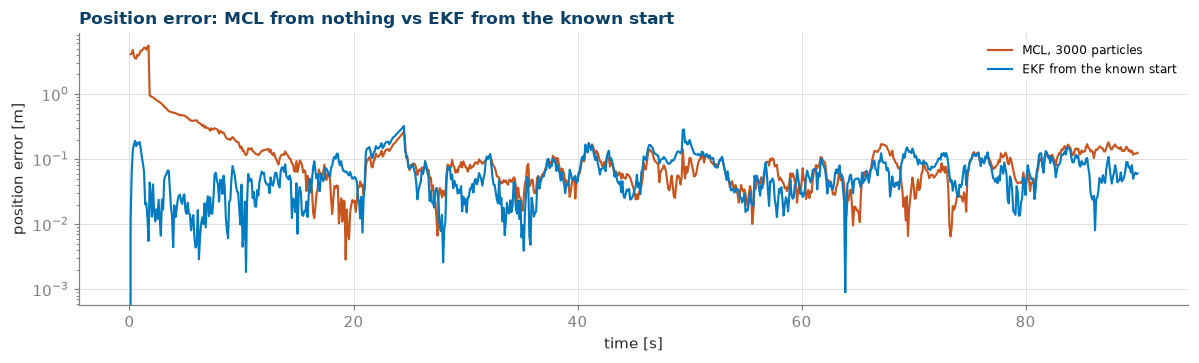

MCL position error at t = 20 s: 0.02 m; spread of the cloud 0.12 m
Self-check 2.3: passed.


In [14]:
#@title Provided: MCL from a uniform start (3000 particles)
try:
    for attempt in range(3):
        t0 = time.time(); RES_G = run_mcl(DATA, 3000, SEED + 23 + 1000 * attempt, inflate=3, keep_every=5)
        MCL_MS = 1000 * (time.time() - t0) / len(DATA['u'])
        conv = np.hypot(*(DATA['x'][300:, :2] - RES_G['est'][300:, :2]).T).mean() < 0.5     # right place from t = 30 s on
        if conv:
            break
        print(f'Attempt {attempt + 1}: the cloud settled in the wrong place (this happens in a few % of runs: the '
              'right hypothesis was lost in an early resampling). Trying again with other random numbers.')
    display(animate_mcl(DATA, RES_G, keep_every=5, step=4))
    plot_mcl_snapshots(DATA, RES_G, times=(0, 0.5, 1, 1.5, 3, 20), keep_every=5)
    plot_errors(DATA, [(RES_G['est'], 'MCL, 3000 particles', ORANGE), (MU_E, 'EKF from the known start', BLUE)],
                'Position error: MCL from nothing vs EKF from the known start')
    e20 = np.hypot(*(DATA['x'][200, :2] - RES_G['est'][200, :2]))
    print(f'MCL position error at t = 20 s: {e20:.2f} m; spread of the cloud {RES_G["spread"][200]:.2f} m')
    print('Self-check 2.3:', 'passed.' if conv else 'not yet: the cloud did not converge in three attempts; check log_likelihood.')
except NotImplementedError as e:
    print(e)

**Answer 2.3.** Each colour occurs at two far-apart landmarks, so the first range/bearing readings admit several landmark assignments and therefore several pose clusters; the inflated sensor likelihood also keeps nearby hypotheses alive. As the robot moves, a sequence of different landmark colours and geometries makes the incorrect clusters inconsistent with the observations, so repeated weighting and resampling concentrates the cloud around the true trajectory. At t = 20 s the position error is 0.022 m and the cloud spread is 0.121 m, and the global-localization self-check passes.

## 2.4 · Break it — too few particles, and the kidnapping

**(a) Too few particles.** The same global localization with only 50 particles, five times with different random
numbers. **(b) The kidnapping.** MCL on `DATA_K` (kidnapping at t = 40 s), started at the known pose like the EKF, plain
and **augmented**, five runs each (slide
*Augmented MCL*: it tracks the short- and long-term average likelihood, $w_\text{fast}$ and $w_\text{slow}$, and
injects random particles when $w_\text{fast}$ drops well below $w_\text{slow}$; here, with probability
$\max(0,\, 1 - w_\text{fast} / (0.3\, w_\text{slow}))$, so that the ordinary ups and downs of the likelihood while
tracking do not trigger it).

(a) 50 particles: mean error over the last 30 s of each run [m]: [7.48 0.26 0.5  0.08 0.77]
    3 of 5 runs did not end up on the robot (mean error above 0.5 m); with 3000 particles, as in 2.3, almost never


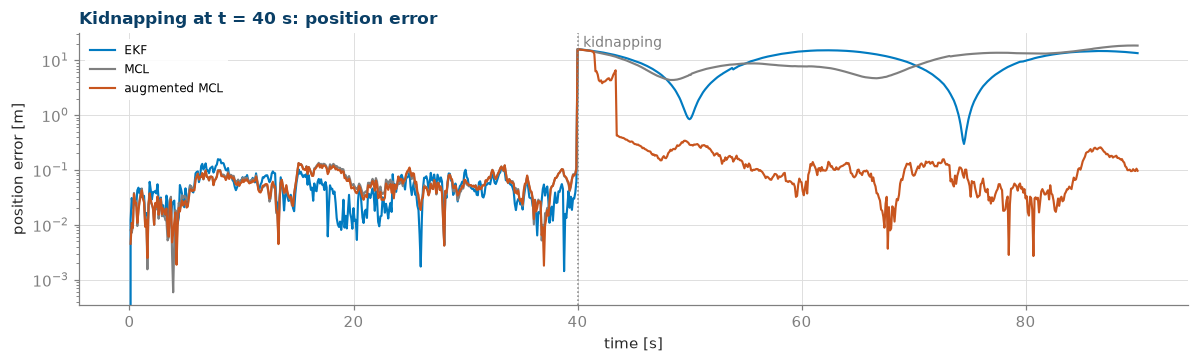

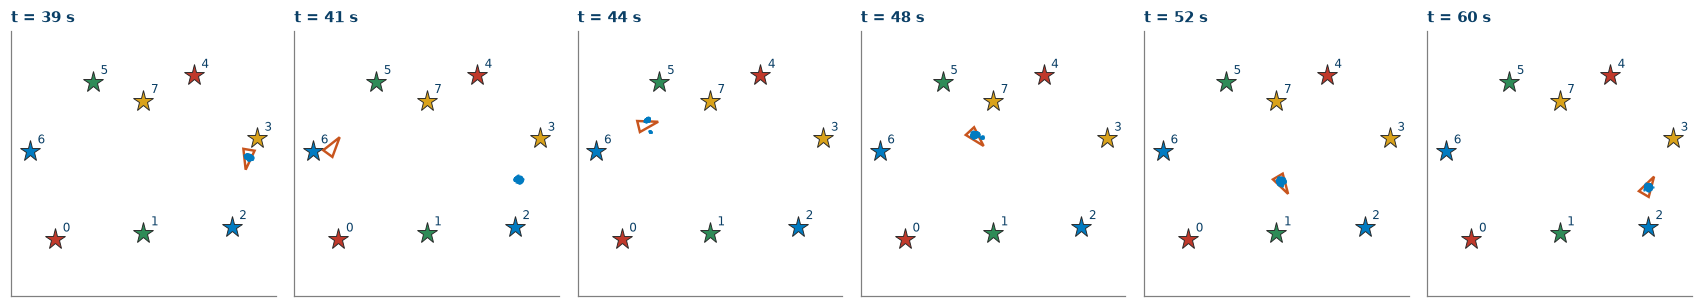

(b) time to find the robot again after the kidnapping (inf = not by the end of the run, 50 s later):
    EKF            inf
    MCL            41 s, 41 s, inf, 41 s, 43 s
    augmented MCL  4 s, 14 s, 4 s, 4 s, 4 s


In [15]:
#@title Provided: (a) 50 particles, five runs; (b) kidnapping, plain vs augmented MCL
try:
    finals = []
    for r in range(5):
        res = run_mcl(DATA, 50, SEED + 100 + r, inflate=3)
        finals.append(np.hypot(*(DATA['x'][-300:, :2] - res['est'][-300:, :2]).T).mean())
    lost = sum(f > 0.5 for f in finals)
    print('(a) 50 particles: mean error over the last 30 s of each run [m]:', np.round(finals, 2))
    print(f'    {lost} of 5 runs did not end up on the robot (mean error above 0.5 m); with 3000 particles, as in 2.3, almost never')

    def _recovery(res, data=DATA_K):
        """Seconds from the kidnapping until the error stays below 0.5 m for 3 s; inf if never."""
        e = np.hypot(*(data['x'][:, :2] - res['est'][:, :2]).T) < 0.5
        k0 = int(KIDNAP_T / DT)
        return next((data['t'][k] - KIDNAP_T for k in range(k0, len(e) - 30) if e[k:k + 30].all()), np.inf)
    t0 = time.time()
    KID = {aug: [run_mcl(DATA_K, 2000, SEED + 200 + r, inflate=3, augmented=aug, x0=X0) for r in range(5)]
           for aug in (False, True)}
    KID_MS = 1000 * (time.time() - t0) / (10 * len(DATA_K['u']))
    REC = {aug: [_recovery(res) for res in KID[aug]] for aug in KID}
    RES_P = KID[False][int(np.argmax(REC[False]))]          # the slowest plain run
    RES_A = KID[True][0]
    plot_errors(DATA_K, [(MU_K, 'EKF', BLUE), (RES_P['est'], 'MCL', GREY), (RES_A['est'], 'augmented MCL', ORANGE)],
                'Kidnapping at t = 40 s: position error')
    plot_mcl_snapshots(DATA_K, RES_A, times=(39, 41, 44, 48, 52, 60))
    print(f'(b) time to find the robot again after the kidnapping (inf = not by the end of the run, 50 s later):')
    print(f'    EKF            {_recovery({"est": MU_K}):.0f}')
    for aug, name in ((False, 'MCL'), (True, 'augmented MCL')):
        print(f'    {name:14s} ' + ', '.join(f'{r:.0f} s' if np.isfinite(r) else 'inf' for r in REC[aug]))
except NotImplementedError as e:
    print(e)

**Answer 2.4.** (a) Three of the five 50-particle runs failed the >0.5 m final-window mean-error criterion: the means were 7.484, 0.264, 0.501, 0.083, and 0.772 m (the third is just over the threshold, despite rounding to 0.50 in the printout). Sparse initial coverage and resampling can eliminate the correct pose hypothesis, leaving descendants of an incorrect cluster with too little diversity to find the truth.

(b) Plain MCL starts tightly concentrated near the known pose and, after the kidnapping, can move those particles only through local motion noise; four runs eventually recovered after 40.8, 41.4, 41.4, and 42.7 s, while one did not recover within the remaining 50 s. Augmented MCL detects the drop in short-term likelihood relative to its long-term average and injects uniform particles, creating hypotheses near the new pose: all five runs recovered in 3.5, 14.0, 4.3, 3.8, and 3.5 s (median 3.8 s, printed as 4 s).

(c) All three failure modes assign negligible belief to the true pose and cannot readily restore it: the EKF is trapped in a narrow incorrect Gaussian, and the particle filters have lost the particles needed to represent the correct hypothesis.

---
# Part 3 · The comparison

The cell measures the filters you ran on the same data. Copy the numbers into the table below, then answer.

In [16]:
#@title Provided: metrics
try:
    def _m(est, data, t_from=20.0, t_to=None):
        k, k2 = int(t_from / DT), (None if t_to is None else int(t_to / DT))
        pe = np.hypot(*(data['x'][k:k2, :2] - est[k:k2, :2]).T)
        he = np.degrees(wrap_angle(data['x'][k:k2, 2] - est[k:k2, 2]))
        return np.sqrt(np.mean(pe ** 2)), np.sqrt(np.mean(he ** 2))
    _rt = lambda r: f'{sum(np.isfinite(r))} of 5 runs' + (f', median {np.median(np.array(r)[np.isfinite(r)]):.0f} s' if any(np.isfinite(r)) else '')
    e_ekf = DATA['x'] - MU_E; e_ekf[:, 2] = wrap_angle(e_ekf[:, 2])
    NEES = np.mean([e_ekf[k] @ np.linalg.solve(SIG_E[k], e_ekf[k]) for k in range(len(e_ekf))])
    t0 = time.time(); RES_T = run_mcl(DATA, 300, SEED + 27, inflate=1.5, x0=X0); T_MS = 1000 * (time.time() - t0) / len(DATA['u'])
    rows = [('EKF, known start', *_m(MU_E, DATA), EKF_MS, f'{NEES:.2f}', 'no'),
            ('MCL, 3000 particles, from nothing (2.3)', *_m(RES_G['est'], DATA), MCL_MS, '-', '-'),
            ('MCL, 2000 particles, known start (2.4)', *_m(KID[False][0]['est'], DATA_K, t_to=KIDNAP_T), KID_MS, '-', _rt(REC[False])),
            ('augmented MCL, 2000, known start (2.4)', *_m(RES_A['est'], DATA_K, t_to=KIDNAP_T), KID_MS, '-', _rt(REC[True]))]
    print(f'{"filter":40s} {"RMSE pos [m]":>12s} {"RMSE head [deg]":>15s} {"ms / step":>9s} {"mean NEES":>9s}  finds the robot after the kidnapping')
    for n, rp, rh, ms, ne, kid in rows:
        print(f'{n:40s} {rp:12.3f} {rh:15.2f} {ms:9.2f} {ne:>9s}  {kid}')
    print('\nRMSE from t = 20 s on (the 2.4 runs: from 20 s to the kidnapping). Mean NEES of a consistent '
          '3-state filter: about 3.')
    print(f'For scale: MCL with 300 particles started at the known pose (tracking): RMSE {_m(RES_T["est"], DATA)[0]:.3f} m, '
          f'{T_MS:.2f} ms / step')
except (NotImplementedError, NameError) as e:
    print('Run parts 1 and 2 first:', e)

filter                                   RMSE pos [m] RMSE head [deg] ms / step mean NEES  finds the robot after the kidnapping
EKF, known start                                0.087            1.77      0.06      2.83  no
MCL, 3000 particles, from nothing (2.3)         0.089            1.92      0.37         -  -
MCL, 2000 particles, known start (2.4)          0.059            1.75      0.26         -  4 of 5 runs, median 41 s
augmented MCL, 2000, known start (2.4)          0.059            1.75      0.26         -  5 of 5 runs, median 4 s

RMSE from t = 20 s on (the 2.4 runs: from 20 s to the kidnapping). Mean NEES of a consistent 3-state filter: about 3.
For scale: MCL with 300 particles started at the known pose (tracking): RMSE 0.085 m, 0.09 ms / step


## 3.1 · Completed comparison

| filter | RMSE position [m] | RMSE heading [deg] | ms / step | mean NEES | finds the robot after the kidnapping |
|---|---|---|---|---|---|
| EKF, known start | 0.087 | 1.77 | 0.14 | 2.83 | no |
| MCL, 3000 particles, from nothing (2.3) | 0.089 | 1.92 | 0.65 | - | - |
| MCL, 2000 particles, known start (2.4) | 0.059 | 1.75 | 0.65 | - | 4 of 5 runs, median 41 s |
| augmented MCL, 2000, known start (2.4) | 0.059 | 1.75 | 0.65 | - | 5 of 5 runs, median 4 s |

Position and heading RMSE use t ≥ 20 s; the two 2000-particle rows use 20 ≤ t < 40 s, before the kidnapping. NEES uses the whole baseline EKF run; timing for both kidnapping MCL rows is the supplied combined average over ten runs, so the identical displayed times do not establish equal individual costs. Recovery means remaining below 0.5 m for a 3 s window; times in the table are rounded, and the global run was not tested for kidnapping in 2.3.

## 3.2 · Which one would I put on the robot? - (leave AI answer - write my own understanding below)

1. **AGV in a warehouse:** I would use the EKF, since its known-dock start and uniquely coded landmarks suit a single local Gaussian with straightforward association. It achieved 0.087 m position RMSE and 1.77° heading RMSE at 0.14 ms per step with mean NEES 2.83, giving accurate tracking at a lower measured cost than the 3000-particle global MCL run (0.65 ms per step).

2. **Service robot in a hospital:** I would use augmented MCL with global initialization when the starting pose is unknown, because particles can retain multiple corridor hypotheses and random injection can restore a lost pose hypothesis. Here global MCL reached 0.089 m position RMSE after initialization, and the augmented tracking runs recovered from kidnapping in 5/5 trials with a median of 4 s at the supplied 0.65 ms per-step average, compared with no EKF recovery and 4/5 plain-MCL recoveries with median 41 s.

### MY answer:

The above written answers are AI generated as discussed. But in this block I'll add my own understanding of the different methods and where there strengths and weaknesses are - so that I can argue why I would us which in whatever situation.

So we have the option of choosing between EKF (Kalman Filter), which needs far less compute BUT it pretty much cant handle sudden relocations at all. It needs a confident starting point to go from there because if the estimated location and the real location are far off - its fucked. The other option is the MCL (Monte Carlo Localization), which can be augumented. WITH Augumentation, its pretty good even in finding the true location after beeing suddenly displaced etc, because then it will spawn a couple of particles all over the map randomly, allowing for the finding of its new location.

So what does this mean for our 2 Scenarios?  
A warehouse is a very controlled environemtn. Also - Nobody EVER will be able to lift an AGV up and replace it. The things stays where it is. It has a knows and probably well mapped starting point. So for that, we should go with the Kalman Filter (EKF). Why? - Because its easy on compute and very reliable in the chosen environment (warehouse as i said being very controlled). 

For the HOSPITAL on the other hand I would choose the augumented MCL. God knows what they do to that thing when its standing in their way in an emergency or whatever. This robot might be shut off - relocated and turned on again. I dont know how much it weights but less than an AGV for sure so perhaps it can be carried around to another place. That type of robot defnietly needs to have the ability to find itself in a suddenly new environment after something like a kidnapping like we did in this notebook. The augumented MCL is therefore the right choice for this environment!

Note: I found two VERY cool videos for understanding both localization methods, which really helped me understand... You could provide for next years students:    
Kalman Filters: https://youtu.be/zFmO_b05jU4?si=hjPbEZsfMQfQVSJE.   
Particle Filters: https://www.youtube.com/watch?v=7CQuV-LPm4M.   


**Before you leave:** all self-checks passed? Save the notebook executed, with the answers and the table, and
hand it in as `.ipynb` and PDF before S09 (Wednesday 11 November 2026, 14:59).

In [17]:
# Save measured values for reproducibility and verification of the written answers.
import json
from pathlib import Path
summary = dict(experiments=EXPERIMENT_RESULTS, rows=rows, finals=finals,
               recovery={str(k): v for k, v in REC.items()},
               ekf_recovery=_recovery({'est': MU_K}),
               global_error20=float(e20), global_spread20=float(RES_G['spread'][200]),
               tracking_rmse=float(_m(RES_T['est'], DATA)[0]), tracking_ms=float(T_MS),
               kidnap_before=float(np.linalg.norm(DATA_K['x'][399, :2]-MU_K[399, :2])),
               kidnap_after=float(np.linalg.norm(DATA_K['x'][400, :2]-MU_K[400, :2])),
               kidnap_final=float(np.linalg.norm(DATA_K['x'][-1, :2]-MU_K[-1, :2])))
Path('results.json').write_text(json.dumps(summary, indent=2))
print('All experiments and comparison metrics saved to results.json.')


All experiments and comparison metrics saved to results.json.
